In [ ]:
!pip install -q pingouin

In [ ]:
# -*- coding: utf-8 -*-
"""
Burnout Prediction — Student Wellness Index Study
==================================================

Experimental Design:
  Model A : Raw Features  → Random Forest
  Model B : Raw Features  → SVM
  Model C : Academic + SWI → Random Forest
  Model D : Academic + SWI → SVM
  Model E : SWI Only      → Random Forest
  Model F : SWI Only      → SVM

All models share the same train/test split and the same
StratifiedKFold object so results are directly comparable.
"""

# ──────────────────────────────────────────────────────────────
# Install dependencies
# ──────────────────────────────────────────────────────────────
# @title 1. Install & Import

# !pip install -q pingouin

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_validate, RandomizedSearchCV
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, ConfusionMatrixDisplay, confusion_matrix
)
from sklearn.feature_selection import mutual_info_classif
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pingouin as pg

# Reproducibility seed — never change this
SEED = 42
np.random.seed(SEED)

print("All libraries loaded successfully.")


All libraries loaded successfully.


In [ ]:
# ──────────────────────────────────────────────────────────────
#  Load data
# ──────────────────────────────────────────────────────────────
# @title 2. Load Dataset

df = pd.read_csv("data.csv")

print(f"Shape: {df.shape}")
print(f"Columns ({len(df.columns)}):\n{df.columns.tolist()}")

Shape: (132, 48)
Columns (48):
['Timestamp', 'Age', 'Gender', 'education_lvl', 'Sleep_hr', 'Screen_hr', 'Study_hr', 'Courses', 'Attendance', 'cgpa', 'EX_hr', 'Parttime_job', 'B1', 'B2', 'B3', 'B4', 'B5', 'S1', 'S2', 'S3', 'S4', 'S5', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'SS1', 'SS2', 'SS3', 'SS4', 'SS5', 'L1', 'L2', 'L3', 'L4', 'L5', 'consent']


In [ ]:
# ──────────────────────────────────────────────────────────────
# Basic cleaning
# ──────────────────────────────────────────────────────────────
# @title 3. Drop Irrelevant Columns & Check Nulls

df.drop(columns=['Timestamp', 'consent',], inplace=True)
pd.set_option('display.max_columns', None)

print("Null values per column:")
print(df.isna().sum())
print(f"\nTotal nulls: {df.isna().sum().sum()}")
print("\nFirst 5 rows:")
df.head()


Null values per column:
Age              0
Gender           0
education_lvl    0
Sleep_hr         0
Screen_hr        0
Study_hr         0
Courses          0
Attendance       0
cgpa             0
EX_hr            0
Parttime_job     0
B1               0
B2               0
B3               0
B4               0
B5               0
S1               0
S2               0
S3               0
S4               0
S5               0
D1               0
D2               0
D3               0
D4               0
D5               0
D6               0
D7               0
D8               0
A1               0
A2               0
A3               0
A4               0
A5               0
A6               0
A7               0
SS1              0
SS2              0
SS3              0
SS4              0
SS5              0
L1               0
L2               0
L3               0
L4               0
L5               0
dtype: int64

Total nulls: 0

First 5 rows:


,Age,Gender,education_lvl,Sleep_hr,Screen_hr,Study_hr,Courses,Attendance,cgpa,EX_hr,Parttime_job,B1,B2,B3,B4,B5,S1,S2,S3,S4,S5,D1,D2,D3,D4,D5,D6,D7,D8,A1,A2,A3,A4,A5,A6,A7,SS1,SS2,SS3,SS4,SS5,L1,L2,L3,L4,L5
0,19,Female,Undergraduate,7-8,more than 8,more than 30,4,60-70,6.0 - 6.9,more than 6,no,4,6,6,6,0,4,3,2,3,3,3,3,3,3,3,3,3,3,3,3,5,3,3,2,1,7,3,4,1,7,7,7,4,7,7
1,19,Female,Undergraduate,6-7,4-6,less than 5,3 or less,70-80,7.0 - 7.9,none,no,5,5,4,6,2,2,2,3,2,3,2,3,3,3,3,3,2,3,3,3,5,3,3,3,3,7,3,2,7,1,7,1,5,1,4
2,21,Male,Undergraduate,7-8,2-4,5-10,4,90-100,9.0 - 10.0,2-4,no,3,5,1,5,0,3,3,1,3,2,1,3,1,1,1,1,2,2,1,2,4,1,3,0,1,7,7,7,7,7,4,6,6,7,7
3,23,Female,Undergraduate,7-8,2-4,16-20,3 or less,80-90,8.0 - 8.9,less than 1,no,4,3,3,6,0,2,2,2,3,3,0,0,0,2,0,1,1,0,0,0,1,1,1,1,1,6,7,7,7,7,7,7,7,7,7
4,22,Male,Undergraduate,7-8,2-4,16-20,5,80-90,6.0 - 6.9,less than 1,yes,3,5,2,3,3,0,2,3,0,4,1,2,2,0,0,0,0,0,1,1,1,0,0,0,0,4,7,7,7,1,6,3,5,4,4


In [ ]:
# ──────────────────────────────────────────────────────────────
# Reverse scoring
# ──────────────────────────────────────────────────────────────
# @title 4. Reverse Scoring

# B4 is reverse-scored on a 1–5 scale (max = 6 - score)
df["B4"] = 6 - df["B4"]

# S3 and S5 are reverse-scored on a 1–4 scale (max = 4 - score + 1 = 5 - score)
df["S5"] = 4 - df["S5"]
df["S3"] = 4 - df["S3"]

print("Reverse scoring applied to B4, S3, S5.")
print("\nDescriptive stats after reverse scoring:")
print(df[["B4", "S3", "S5"]].describe().round(2))

Reverse scoring applied to B4, S3, S5.

Descriptive stats after reverse scoring:
           B4      S3      S5
count  132.00  132.00  132.00
mean     2.51    2.06    2.05
std      1.86    1.17    1.20
min      0.00    0.00    0.00
25%      1.00    1.00    1.00
50%      2.00    2.00    2.00
75%      4.00    3.00    3.00
max      6.00    4.00    4.00


In [ ]:
# ──────────────────────────────────────────────────────────────
# Cronbach's Alpha (reliability check)
# ──────────────────────────────────────────────────────────────
# @title 5. Cronbach's Alpha — Scale Reliability

scales = {
    "Burnout (adapted)"         : ['B1','B2','B3','B4','B5'],
    "Stress (adapted PSS)"      : ['S1','S2','S3','S4','S5'],
    "Depression (PHQ-8)"        : ['D1','D2','D3','D4','D5','D6','D7','D8'],
    "Self-Regulated Learning"   : ['L1','L2','L3','L4','L5'],
    "Anxiety (GAD adapted)"     : ['A1','A2','A3','A4','A5','A6','A7'],
    "Social Support (MSPSS)"    : ['SS1','SS2','SS3','SS4','SS5'],
}

alpha_results = {}
print(f"{'Scale':<35} {'Alpha':>8}  {'95% CI':<20}  {'Acceptable?'}")
print("-" * 75)
for name, items in scales.items():
    alpha, ci = pg.cronbach_alpha(data=df[items])
    acceptable = "✓ Yes" if alpha >= 0.70 else "✗ Below 0.70"
    alpha_results[name] = round(alpha, 3)
    print(f"{name:<35} {alpha:>8.3f}  {str(ci):<20}  {acceptable}")

print("\nNote: Burnout scale alpha < 0.70 is a known limitation.")
print("All results should be interpreted with this caveat.")


Scale                                  Alpha  95% CI                Acceptable?
---------------------------------------------------------------------------
Burnout (adapted)                      0.654  [0.551 0.739]         ✗ Below 0.70
Stress (adapted PSS)                   0.620  [0.507 0.714]         ✗ Below 0.70
Depression (PHQ-8)                     0.798  [0.741 0.846]         ✓ Yes
Self-Regulated Learning                0.721  [0.638 0.79 ]         ✓ Yes
Anxiety (GAD adapted)                  0.886  [0.854 0.913]         ✓ Yes
Social Support (MSPSS)                 0.781  [0.716 0.835]         ✓ Yes

Note: Burnout scale alpha < 0.70 is a known limitation.
All results should be interpreted with this caveat.


In [ ]:
# ──────────────────────────────────────────────────────────────
# Compute subscale scores
# ──────────────────────────────────────────────────────────────
# @title 6. Compute Subscale Scores

df["burnout_score"]    = df[['B1','B2','B3','B4','B5']].sum(axis=1)
df["stress_score"]     = df[['S1','S2','S3','S4','S5']].sum(axis=1)
df["anxiety_score"]    = df[['A1','A2','A3','A4','A5','A6','A7']].sum(axis=1)
df["depression_score"] = df[['D1','D2','D3','D4','D5','D6','D7','D8']].sum(axis=1)
df["SRL_score"]        = df[['L1','L2','L3','L4','L5']].sum(axis=1)
df["Support_score"]    = df[['SS1','SS2','SS3','SS4','SS5']].sum(axis=1)

# Drop raw item columns — keep only composites
item_cols = (
    ['B1','B2','B3','B4','B5'] + ['S1','S2','S3','S4','S5'] +
    ['A1','A2','A3','A4','A5','A6','A7'] +
    ['D1','D2','D3','D4','D5','D6','D7','D8'] +
    ['L1','L2','L3','L4','L5'] + ['SS1','SS2','SS3','SS4','SS5']
)
df_ml = df.drop(columns=item_cols)

print("Subscale score ranges:")
score_cols = ["burnout_score","stress_score","anxiety_score",
              "depression_score","SRL_score","Support_score"]
print(df_ml[score_cols].describe().round(2))



Subscale score ranges:
       burnout_score  stress_score  anxiety_score  depression_score  \
count         132.00        132.00         132.00            132.00   
mean           16.51         11.69          12.74             12.88   
std             6.06          3.71           5.76              5.19   
min             0.00          0.00           1.00              1.00   
25%            13.00          9.00           8.00             10.00   
50%            17.00         12.00          13.00             12.50   
75%            21.00         14.00          17.00             16.00   
max            29.00         20.00          23.00             24.00   

       SRL_score  Support_score  
count     132.00         132.00  
mean       23.80          22.89  
std         5.67           7.40  
min         7.00           6.00  
25%        20.00          17.75  
50%        24.00          23.00  
75%        28.00          29.00  
max        35.00          35.00  


In [ ]:
# ──────────────────────────────────────────────────────────────
# Encode categorical variables
# ──────────────────────────────────────────────────────────────
# @title 7. Encode Categorical Variables

# Sleep hours
sleep_map = {
    "less than 4": 3.0, "4-5": 4.5, "5-6": 5.5,
    "6-7": 6.5, "7-8": 7.5, "more than 8": 9.0
}
df_ml["Sleep_hr"] = df_ml["Sleep_hr"].map(sleep_map)

# Study hours
study_map = {
    "less than 5": 4.0, "5-10": 7.5, "11-15": 12.5,
    "16-20": 17.5, "21-25": 22.5, "26-30": 27.5, "more than 30": 40.0
}
df_ml["Study_hr"] = df_ml["Study_hr"].map(study_map)

# Exercise hours
ex_map = {
    'none': 0, 'less than 1': 0.5, '1-2': 1.5,
    '2-4': 3.0, '4-6': 5.0, 'more than 6': 6.5
}
df_ml["EX_hr"] = df_ml["EX_hr"].map(ex_map)

# CGPA
cgpa_map = {
    "below 5": 2.5, "5.0 - 5.9": 5.5, "6.0 - 6.9": 6.5,
    "7.0 - 7.9": 7.5, "8.0 - 8.9": 8.5, "9.0 - 10.0": 9.5
}
df_ml["cgpa"] = df_ml["cgpa"].map(cgpa_map)

# Attendance
attendance_map = {
    "less than 50%": 45, "50-60": 55, "60-70": 65,
    "70-80": 75, "80-90": 85, "90-100": 95
}
df_ml["Attendance"] = df_ml["Attendance"].map(attendance_map)

# Screen hours
screen_map = {
    "less than 1": 0.5, "1-2": 1.5, "2-4": 3.0,
    "4-6": 5.0, "6-8": 7.0, "more than 8": 9.0
}
df_ml["Screen_hr"] = df_ml["Screen_hr"].map(screen_map)

# Education level (ordinal)
edu_map = {"high school": 0, "Undergraduate": 1, "post graduate": 2, "phd": 3}
df_ml["education_lvl"] = df_ml["education_lvl"].map(edu_map)

# Courses (ordinal)
courses_map = {"3 or less": 0, "4": 1, "5": 2, "6": 3, "7 or more": 4}
df_ml["Courses"] = df_ml["Courses"].map(courses_map)

# Binary
df_ml["Gender"]      = df_ml["Gender"].map({'Female': 0, 'Male': 1, 'Prefer not to say': 2})
df_ml["Parttime_job"]= df_ml["Parttime_job"].map({'yes': 1, 'no': 0})

print("Encoding complete. Remaining nulls after mapping:")
print(df_ml.isna().sum()[df_ml.isna().sum() > 0])
print(f"\nDataframe shape: {df_ml.shape}")

Encoding complete. Remaining nulls after mapping:
Series([], dtype: int64)

Dataframe shape: (132, 17)


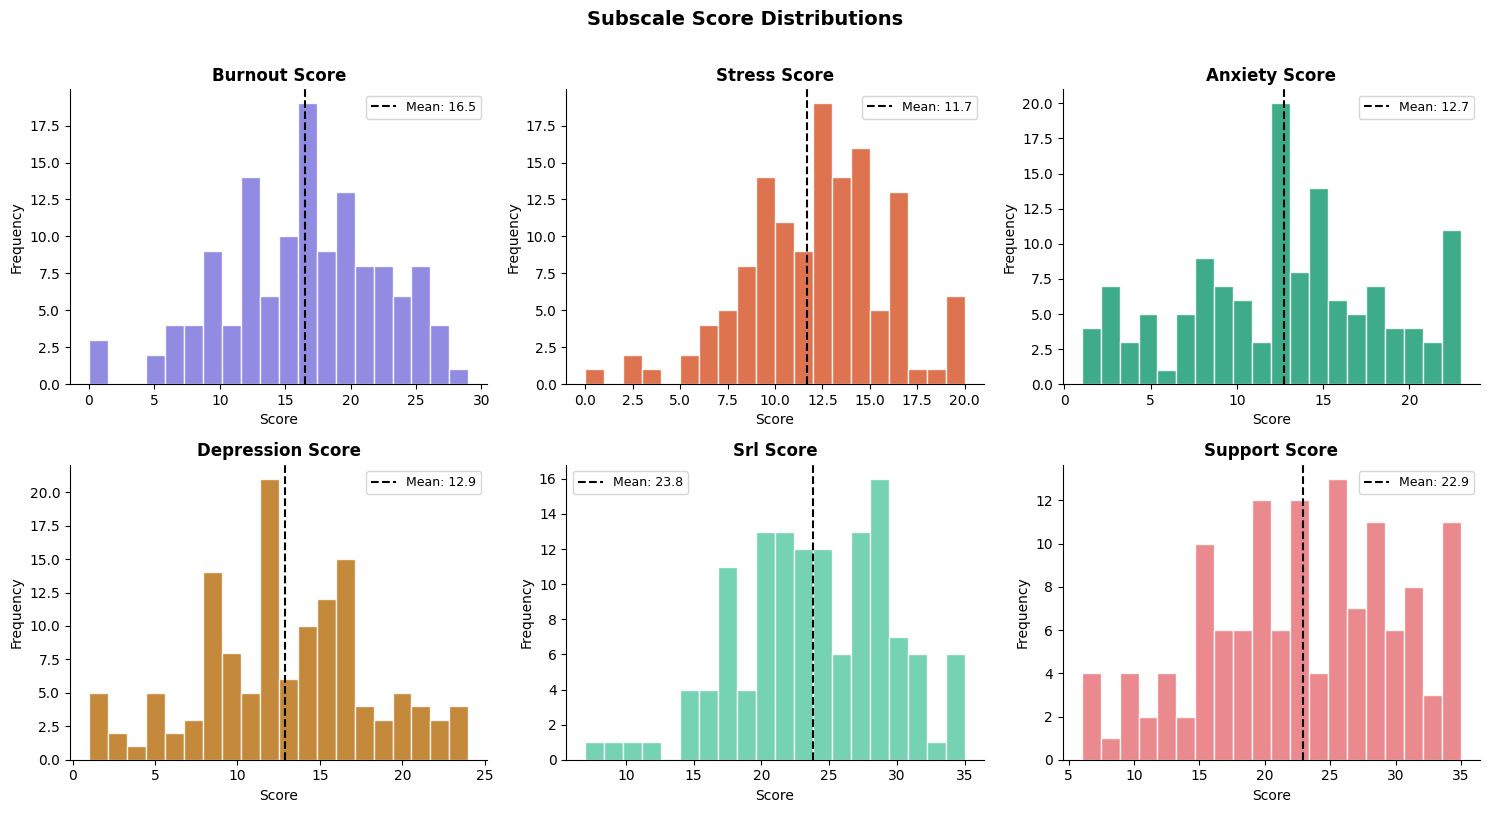

In [ ]:
# ──────────────────────────────────────────────────────────────
# Descriptive statistics & histograms
# ──────────────────────────────────────────────────────────────
# @title 8. EDA — Score Distributions

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
colors = ['#7F77DD','#D85A30','#1D9E75','#BA7517','#5DCAA5','#E8767A']

for i, (col, color) in enumerate(zip(score_cols, colors)):
    axes[i].hist(df_ml[col], bins=20, color=color, alpha=0.85, edgecolor='white')
    axes[i].axvline(df_ml[col].mean(), color='black', linestyle='--',
                    linewidth=1.5, label=f'Mean: {df_ml[col].mean():.1f}')
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Score')
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=9)
    axes[i].spines[['top','right']].set_visible(False)

plt.suptitle('Subscale Score Distributions', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('score_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

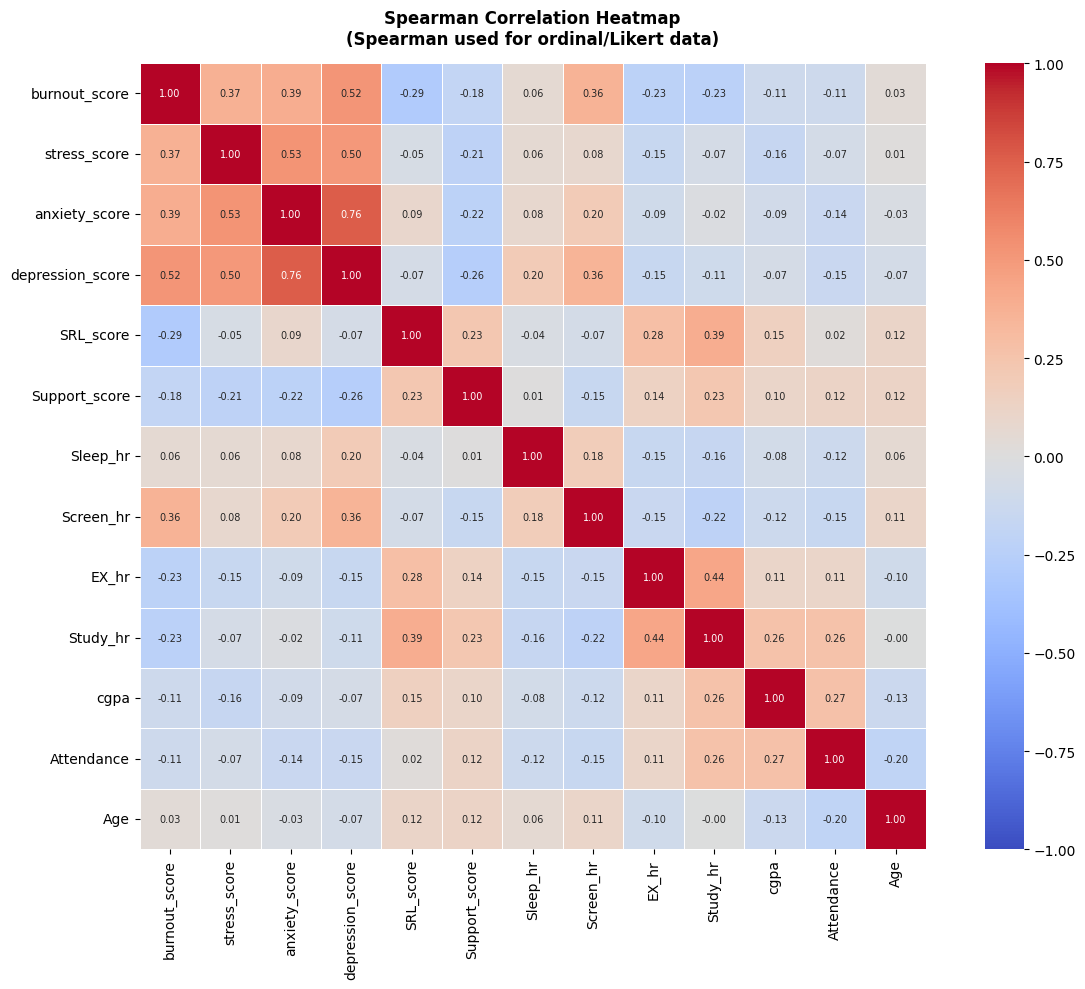

In [ ]:
# ──────────────────────────────────────────────────────────────
# Correlation heatmap
# ──────────────────────────────────────────────────────────────
# @title 9. Spearman Correlation Heatmap

heatmap_cols = [
    "burnout_score", "stress_score", "anxiety_score", "depression_score",
    "SRL_score", "Support_score", "Sleep_hr", "Screen_hr", "EX_hr",
    "Study_hr", "cgpa", "Attendance", "Age"
]

corr = df_ml[heatmap_cols].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, linewidths=0.5, square=True,
    annot_kws={"size": 7}
)
plt.title("Spearman Correlation Heatmap\n(Spearman used for ordinal/Likert data)",
          fontsize=12, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Burnout_Level distribution:
Burnout_Level
Low       46
High      44
Medium    42
Name: count, dtype: int64

Adjusted Rand Index (K-Means vs qcut labels): 0.117
Interpretation:
  ARI > 0.5  → K-Means clusters align well with our labels (good)
  ARI 0.3–0.5 → Moderate alignment (acceptable)
  ARI < 0.3  → Labels may be arbitrary (limitation to report)


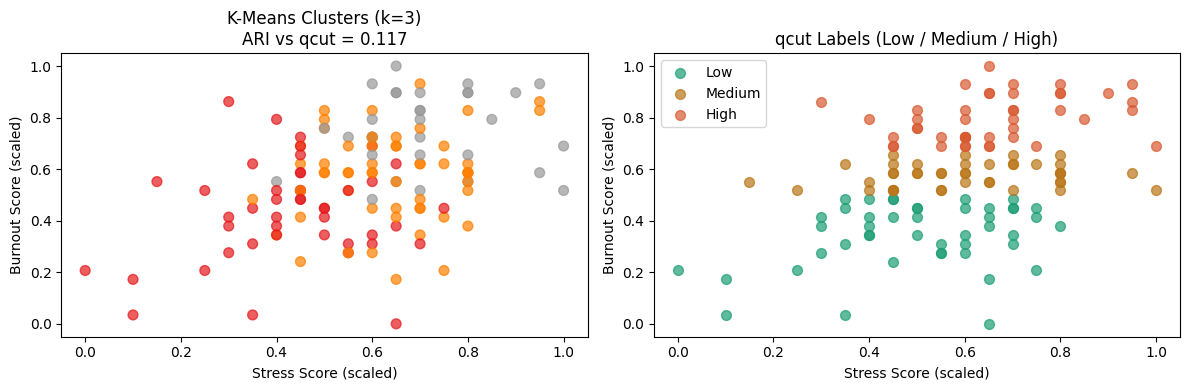

In [ ]:
# ──────────────────────────────────────────────────────────────
# Target variable construction + K-Means validation
# ──────────────────────────────────────────────────────────────
# @title 10. Target Variable — Burnout Level + K-Means Validation

# Construct target using quartile-based thresholds
df_ml["Burnout_Level"] = pd.qcut(
    df_ml["burnout_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

print("Burnout_Level distribution:")
print(df_ml["Burnout_Level"].value_counts())

# ── K-Means validation of target boundaries ──────────────────
# If clusters roughly match our qcut labels, the boundaries are defensible
psych_cols = ["stress_score", "anxiety_score", "depression_score", "burnout_score"]
psych_scaled = MinMaxScaler().fit_transform(df_ml[psych_cols])

kmeans = KMeans(n_clusters=3, random_state=SEED, n_init=20)
cluster_labels = kmeans.fit_predict(psych_scaled)

# Encode our qcut labels numerically for ARI
le_ari = LabelEncoder()
qcut_numeric = le_ari.fit_transform(df_ml["Burnout_Level"])

ari = adjusted_rand_score(qcut_numeric, cluster_labels)
print(f"\nAdjusted Rand Index (K-Means vs qcut labels): {ari:.3f}")
print("Interpretation:")
print("  ARI > 0.5  → K-Means clusters align well with our labels (good)")
print("  ARI 0.3–0.5 → Moderate alignment (acceptable)")
print("  ARI < 0.3  → Labels may be arbitrary (limitation to report)")

# Visualise cluster vs label alignment
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(psych_scaled[:, 0], psych_scaled[:, 3],
                c=cluster_labels, cmap='Set1', alpha=0.7, s=50)
axes[0].set_title(f'K-Means Clusters (k=3)\nARI vs qcut = {ari:.3f}')
axes[0].set_xlabel('Stress Score (scaled)')
axes[0].set_ylabel('Burnout Score (scaled)')

color_map = {"Low": "#1D9E75", "Medium": "#BA7517", "High": "#D85A30"}
for level, color in color_map.items():
    mask = df_ml["Burnout_Level"] == level
    axes[1].scatter(psych_scaled[mask, 0], psych_scaled[mask, 3],
                    label=level, color=color, alpha=0.7, s=50)
axes[1].set_title('qcut Labels (Low / Medium / High)')
axes[1].set_xlabel('Stress Score (scaled)')
axes[1].set_ylabel('Burnout Score (scaled)')
axes[1].legend()

plt.tight_layout()
plt.savefig('kmeans_vs_qcut.png', dpi=150, bbox_inches='tight')
plt.show()


Mutual Information Scores:
         Feature  MI Score
   education_lvl  0.106704
depression_score  0.084564
       SRL_score  0.083747
   anxiety_score  0.075122
         Courses  0.063165
      Attendance  0.059810
       Screen_hr  0.056139
    Parttime_job  0.055529
    stress_score  0.038496
   Support_score  0.010055
            cgpa  0.000000
        Sleep_hr  0.000000
        Study_hr  0.000000
           EX_hr  0.000000
             Age  0.000000


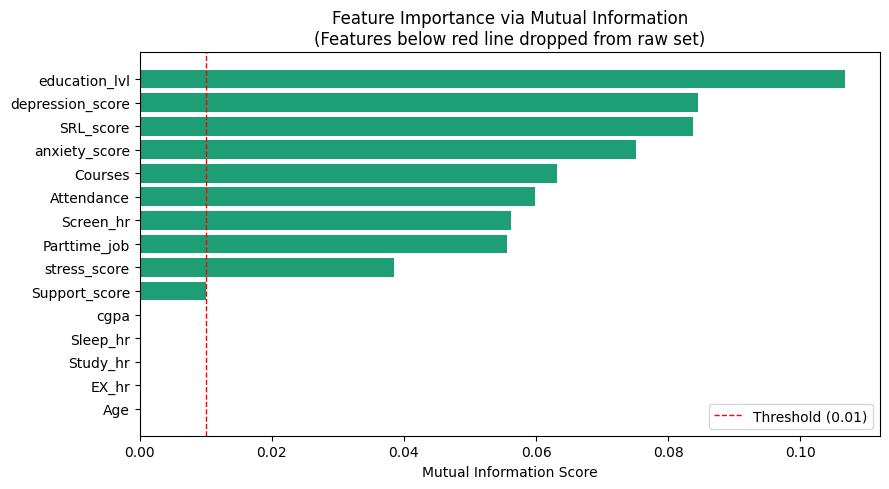


Dropped features (MI < 0.01): ['cgpa', 'Sleep_hr', 'Study_hr', 'EX_hr', 'Age']


In [ ]:
# ──────────────────────────────────────────────────────────────
# Mutual Information feature selection
# ──────────────────────────────────────────────────────────────
# @title 11. Mutual Information — Feature Selection

# Full raw feature set (before MI filtering)
all_raw_features = [
    'stress_score', 'anxiety_score', 'depression_score', 'SRL_score',
    'Support_score', 'Screen_hr', 'cgpa', 'EX_hr', 'Attendance',
    'Study_hr', 'Sleep_hr', 'Age', 'education_lvl',
    'Parttime_job', 'Courses'
]

y = df_ml["Burnout_Level"]
X_all = df_ml[all_raw_features]

mi = mutual_info_classif(X_all, y, random_state=SEED)
mi_df = (pd.DataFrame({"Feature": all_raw_features, "MI Score": mi})
           .sort_values("MI Score", ascending=False)
           .reset_index(drop=True))

print("Mutual Information Scores:")
print(mi_df.to_string(index=False))

# Plot MI scores
plt.figure(figsize=(9, 5))
colors_mi = ['#1D9E75' if s > 0 else '#D85A30' for s in mi_df["MI Score"]]
bars = plt.barh(mi_df["Feature"], mi_df["MI Score"], color=colors_mi)
plt.axvline(0.01, color='red', linestyle='--', linewidth=1,
            label='Threshold (0.01)')
plt.xlabel('Mutual Information Score')
plt.title('Feature Importance via Mutual Information\n'
          '(Features below red line dropped from raw set)')
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.savefig('mutual_information.png', dpi=150, bbox_inches='tight')
plt.show()

# Drop zero/near-zero MI features
zero_mi_features = mi_df[mi_df["MI Score"] < 0.01]["Feature"].tolist()
print(f"\nDropped features (MI < 0.01): {zero_mi_features}")


In [ ]:
# ──────────────────────────────────────────────────────────────
# Define three feature sets
# ──────────────────────────────────────────────────────────────
# @title 12. Define Feature Sets (Raw / SWI / Academic+SWI)

# ── Feature Set A: Raw (MI-filtered psychological + academic + lifestyle) ──
raw_features = [f for f in all_raw_features if f not in zero_mi_features]
print(f"Raw feature set ({len(raw_features)} features): {raw_features}")

# ── Build SWI ──────────────────────────────────────────────────
# SWI = Psychological + Lifestyle + Social Support ONLY
# Academic variables stay separate (conceptually distinct)

df_swi = df_ml.copy()

swi_input_cols = [
    "stress_score", "anxiety_score", "depression_score",  # Psychological
    "Support_score",                                        # Social Support
    "EX_hr", "Screen_hr", "Sleep_hr"                       # Lifestyle
]

scaler_swi = MinMaxScaler()
swi_scaled = pd.DataFrame(
    scaler_swi.fit_transform(df_swi[swi_input_cols]),
    columns=swi_input_cols,
    index=df_swi.index
)

# Invert negative-direction features (higher = worse wellness)
swi_scaled["stress_score"]     = 1 - swi_scaled["stress_score"]
swi_scaled["anxiety_score"]    = 1 - swi_scaled["anxiety_score"]
swi_scaled["depression_score"] = 1 - swi_scaled["depression_score"]
swi_scaled["Screen_hr"]        = 1 - swi_scaled["Screen_hr"]

# Compute SWI dimensions
swi_scaled["Psych_dim"]     = swi_scaled[["stress_score",
                                           "anxiety_score",
                                           "depression_score"]].mean(axis=1)
swi_scaled["Support_dim"]   = swi_scaled["Support_score"]
swi_scaled["Lifestyle_dim"] = swi_scaled[["EX_hr",
                                           "Screen_hr",
                                           "Sleep_hr"]].mean(axis=1)

# Equal-weighted SWI (0-100 scale)
# Weights: Psych=40%, Lifestyle=30%, Support=30%
# (Psych weighted higher — most directly linked to burnout in literature)
df_ml["SWI"] = 100 * (
    0.40 * swi_scaled["Psych_dim"]     +
    0.30 * swi_scaled["Lifestyle_dim"] +
    0.30 * swi_scaled["Support_dim"]
)

print("\nSWI descriptive stats:")
print(df_ml["SWI"].describe().round(2))
print("\nMean SWI by Burnout Level (should decrease Low→High):")
print(df_ml.groupby("Burnout_Level")["SWI"].mean().round(2))

# SWI dimension breakdown by level (for the paper)
dim_cols = ["Psych_dim", "Lifestyle_dim", "Support_dim"]
df_ml[dim_cols] = swi_scaled[dim_cols].values
print("\nDimension means by Burnout Level:")
print(df_ml.groupby("Burnout_Level")[dim_cols].mean().round(3))


# ── Feature Set B: SWI Only ──────────────────────────────────
swi_only_features = ["SWI"]
print(f"\nSWI-only feature set: {swi_only_features}")

# ── Feature Set C: Academic + SWI ────────────────────────────
academic_features = ["cgpa", "Study_hr", "Attendance", "SRL_score"]
acad_swi_features = academic_features + ["SWI"]
print(f"Academic+SWI feature set ({len(acad_swi_features)} features): {acad_swi_features}")

Raw feature set (10 features): ['stress_score', 'anxiety_score', 'depression_score', 'SRL_score', 'Support_score', 'Screen_hr', 'Attendance', 'education_lvl', 'Parttime_job', 'Courses']

SWI descriptive stats:
count    132.00
mean      49.95
std       14.34
min       18.37
25%       39.55
50%       49.83
75%       60.33
max       82.98
Name: SWI, dtype: float64

Mean SWI by Burnout Level (should decrease Low→High):
Burnout_Level
Low       57.65
Medium    48.81
High      42.98
Name: SWI, dtype: float64

Dimension means by Burnout Level:
               Psych_dim  Lifestyle_dim  Support_dim
Burnout_Level                                       
Low                0.559          0.536        0.640
Medium             0.457          0.455        0.563
High               0.345          0.432        0.541

SWI-only feature set: ['SWI']
Academic+SWI feature set (5 features): ['cgpa', 'Study_hr', 'Attendance', 'SRL_score', 'SWI']


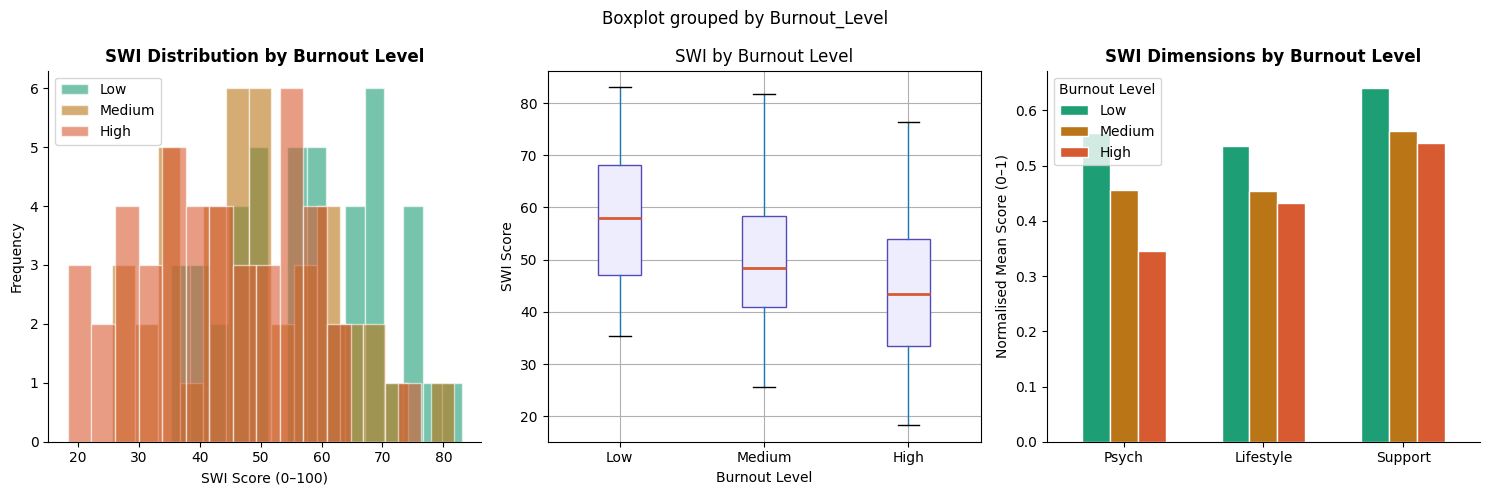


One-way ANOVA — SWI across Burnout Levels:
  F = 14.404, p = 0.0000
  ✓ SWI differs significantly across levels.


In [ ]:

# ──────────────────────────────────────────────────────────────
# SWI visualisation
# ──────────────────────────────────────────────────────────────
# @title 13. SWI Visualisation

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. SWI distribution by burnout level
for level, color in color_map.items():
    mask = df_ml["Burnout_Level"] == level
    axes[0].hist(df_ml.loc[mask, "SWI"], bins=15, alpha=0.6,
                 label=level, color=color, edgecolor='white')
axes[0].set_title('SWI Distribution by Burnout Level', fontweight='bold')
axes[0].set_xlabel('SWI Score (0–100)')
axes[0].set_ylabel('Frequency')
axes[0].legend()
axes[0].spines[['top','right']].set_visible(False)

# 2. Boxplot of SWI by burnout level
df_ml.boxplot(column="SWI", by="Burnout_Level", ax=axes[1],
              patch_artist=True,
              boxprops=dict(facecolor='#EEEDFE', color='#534AB7'),
              medianprops=dict(color='#D85A30', linewidth=2))
axes[1].set_title('SWI by Burnout Level', fontweight='bold')
axes[1].set_xlabel('Burnout Level')
axes[1].set_ylabel('SWI Score')
plt.sca(axes[1])
plt.title('SWI by Burnout Level')

# 3. SWI dimension radar-style bar chart by level
dim_means = df_ml.groupby("Burnout_Level")[dim_cols].mean()
dim_means.T.plot(kind='bar', ax=axes[2],
                 color=["#1D9E75","#BA7517","#D85A30"],
                 width=0.6, edgecolor='white')
axes[2].set_title('SWI Dimensions by Burnout Level', fontweight='bold')
axes[2].set_xticklabels([d.replace('_dim','').title()
                          for d in dim_cols], rotation=0)
axes[2].set_ylabel('Normalised Mean Score (0–1)')
axes[2].legend(title='Burnout Level')
axes[2].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('swi_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

# ANOVA: test whether SWI differs significantly across burnout levels
from scipy import stats
groups = [df_ml.loc[df_ml["Burnout_Level"]==lv, "SWI"].values
          for lv in ["Low","Medium","High"]]
f_stat, p_val = stats.f_oneway(*groups)
print(f"\nOne-way ANOVA — SWI across Burnout Levels:")
print(f"  F = {f_stat:.3f}, p = {p_val:.4f}")
print("  ✓ SWI differs significantly across levels." if p_val < 0.05
      else "  ✗ SWI does NOT differ significantly — limitation.")

In [ ]:
# ──────────────────────────────────────────────────────────────
# Fixed infrastructure
# ──────────────────────────────────────────────────────────────
# @title 14. Fixed Train/Test Split & CV Object

# Target
y = df_ml["Burnout_Level"]

# Three feature matrices
X_raw     = df_ml[raw_features]
X_swi     = df_ml[swi_only_features]
X_acad_swi= df_ml[acad_swi_features]

# One fixed split — used by EVERY model
X_tr_raw, X_te_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=SEED, stratify=y
)

# Align SWI and Academic+SWI splits to the SAME indices
X_tr_swi      = X_swi.loc[X_tr_raw.index]
X_te_swi      = X_swi.loc[X_te_raw.index]
X_tr_acad_swi = X_acad_swi.loc[X_tr_raw.index]
X_te_acad_swi = X_acad_swi.loc[X_te_raw.index]

# One fixed CV — used by EVERY model
FIXED_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(f"Training samples : {len(y_train)}")
print(f"Test samples     : {len(y_test)}")
print(f"\nTraining class distribution:")
print(y_train.value_counts())
print(f"\nTest class distribution:")
print(y_test.value_counts())

Training samples : 105
Test samples     : 27

Training class distribution:
Burnout_Level
Low       37
High      35
Medium    33
Name: count, dtype: int64

Test class distribution:
Burnout_Level
Low       9
Medium    9
High      9
Name: count, dtype: int64


In [ ]:
# ──────────────────────────────────────────────────────────────
# Hyperparameter tuning (RandomizedSearchCV on Raw)
# ──────────────────────────────────────────────────────────────
# @title 15. Hyperparameter Tuning via RandomizedSearchCV

# RF parameter space
rf_param_dist = {
    'n_estimators':     [50, 100, 150, 200],
    'max_depth':        [3, 4, 5, None],
    'min_samples_leaf': [3, 4, 5, 6],
    'min_samples_split':[4, 6, 8, 10],
    'max_features':     ['sqrt', 'log2'],
    'class_weight':     ['balanced']
}

# SVM parameter space
svm_param_dist = {
    'svm__C':      [0.01, 0.1, 1, 5, 10],
    'svm__gamma':  ['scale', 'auto', 0.01, 0.1],
    'svm__kernel': ['rbf', 'linear'],
    'svm__class_weight': ['balanced']
}

# Tune RF on Raw features (same best params applied to all feature sets)
rs_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=SEED),
    rf_param_dist,
    n_iter=40,
    cv=FIXED_CV,
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=SEED,
    verbose=0
)
rs_rf.fit(X_tr_raw, y_train)
best_rf_params = rs_rf.best_params_

print("Best RF Parameters:")
for k, v in best_rf_params.items():
    print(f"  {k}: {v}")
print(f"Best RF CV F1 (tuning): {rs_rf.best_score_:.4f}")

# Tune SVM on Raw features
svm_base = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(random_state=SEED))
])
rs_svm = RandomizedSearchCV(
    svm_base,
    svm_param_dist,
    n_iter=30,
    cv=FIXED_CV,
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=SEED,
    verbose=0
)
rs_svm.fit(X_tr_raw, y_train)
best_svm_params = rs_svm.best_params_

print("\nBest SVM Parameters:")
for k, v in best_svm_params.items():
    print(f"  {k}: {v}")
print(f"Best SVM CV F1 (tuning): {rs_svm.best_score_:.4f}")



Best RF Parameters:
  n_estimators: 200
  min_samples_split: 6
  min_samples_leaf: 6
  max_features: sqrt
  max_depth: None
  class_weight: balanced
Best RF CV F1 (tuning): 0.4997

Best SVM Parameters:
  svm__kernel: rbf
  svm__gamma: auto
  svm__class_weight: balanced
  svm__C: 10
Best SVM CV F1 (tuning): 0.5200


In [ ]:
# ──────────────────────────────────────────────────────────────
# Build final models with best params
# ──────────────────────────────────────────────────────────────
# @title 16. Build Final Models (Same Params Across Feature Sets)

def make_rf(params):
    """RF with tuned params — same across all feature sets."""
    return RandomForestClassifier(
        n_estimators    = params.get('n_estimators', 100),
        max_depth       = params.get('max_depth', 4),
        min_samples_leaf= params.get('min_samples_leaf', 4),
        min_samples_split=params.get('min_samples_split', 6),
        max_features    = params.get('max_features', 'sqrt'),
        class_weight    = 'balanced',
        random_state    = SEED
    )

def make_svm(params):
    """SVM pipeline with tuned params — same across all feature sets."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(
            C           = params.get('svm__C', 1),
            gamma       = params.get('svm__gamma', 'scale'),
            kernel      = params.get('svm__kernel', 'rbf'),
            class_weight= 'balanced',
            random_state= SEED
        ))
    ])

# Six models: 2 algorithms × 3 feature sets
experiments = {
    'RF  | Raw':          (make_rf(best_rf_params),   X_raw,      X_tr_raw,      X_te_raw),
    'RF  | SWI Only':     (make_rf(best_rf_params),   X_swi,      X_tr_swi,      X_te_swi),
    'RF  | Acad + SWI':   (make_rf(best_rf_params),   X_acad_swi, X_tr_acad_swi, X_te_acad_swi),
    'SVM | Raw':          (make_svm(best_svm_params),  X_raw,      X_tr_raw,      X_te_raw),
    'SVM | SWI Only':     (make_svm(best_svm_params),  X_swi,      X_tr_swi,      X_te_swi),
    'SVM | Acad + SWI':   (make_svm(best_svm_params),  X_acad_swi, X_tr_acad_swi, X_te_acad_swi),
}

print("Experiment matrix defined:")
for name in experiments:
    print(f"  {name}")


Experiment matrix defined:
  RF  | Raw
  RF  | SWI Only
  RF  | Acad + SWI
  SVM | Raw
  SVM | SWI Only
  SVM | Acad + SWI


In [ ]:

# ──────────────────────────────────────────────────────────────
# Run systematic evaluation
# ──────────────────────────────────────────────────────────────
# @title 17. Systematic Evaluation Pipeline

all_results = []

for exp_name, (model, X_full, X_tr, X_te) in experiments.items():

    # Cross-validation on FULL data with FIXED folds
    cv_out = cross_validate(
        model, X_full, y,
        cv=FIXED_CV,
        scoring={
            'accuracy':    'accuracy',
            'f1_weighted': 'f1_weighted'
        },
        return_train_score=True
    )

    # Final fit on training split, evaluate on held-out test
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    algo, feat_set = exp_name.split(' | ')

    all_results.append({
        'Algorithm':      algo.strip(),
        'Feature Set':    feat_set.strip(),
        'CV Acc (mean)':  round(cv_out['test_accuracy'].mean(), 4),
        'CV Acc (±std)':  round(cv_out['test_accuracy'].std(), 4),
        'CV F1 (mean)':   round(cv_out['test_f1_weighted'].mean(), 4),
        'Train Acc':      round(cv_out['train_accuracy'].mean(), 4),
        'Overfit Gap':    round(cv_out['train_accuracy'].mean() -
                               cv_out['test_accuracy'].mean(), 4),
        'Test Accuracy':  round(accuracy_score(y_test, y_pred), 4),
        'Test F1':        round(f1_score(y_test, y_pred, average='weighted'), 4),
        'Test Precision': round(precision_score(y_test, y_pred, average='weighted'), 4),
        'Test Recall':    round(recall_score(y_test, y_pred, average='weighted'), 4),
    })

results_df = pd.DataFrame(all_results)

print("\n" + "="*100)
print("FULL COMPARISON TABLE")
print("="*100)
print(results_df.to_string(index=False))
print("\nNote: CV Acc (mean) is the PRIMARY metric with small n.")
print("Test Accuracy is informative but based on only ~23 samples.")


FULL COMPARISON TABLE
Algorithm Feature Set  CV Acc (mean)  CV Acc (±std)  CV F1 (mean)  Train Acc  Overfit Gap  Test Accuracy  Test F1  Test Precision  Test Recall
       RF         Raw         0.4994         0.0487        0.4811     0.7538       0.2544         0.5926   0.5807          0.5962       0.5926
       RF    SWI Only         0.3932         0.0607        0.3849     0.6174       0.2243         0.4815   0.4754          0.4848       0.4815
       RF  Acad + SWI         0.3932         0.0556        0.3817     0.7405       0.3473         0.4444   0.4404          0.4515       0.4444
      SVM         Raw         0.4929         0.0867        0.4850     0.9603       0.4674         0.4815   0.4698          0.4722       0.4815
      SVM    SWI Only         0.4917         0.0622        0.4901     0.5076       0.0158         0.3704   0.3030          0.2564       0.3704
      SVM  Acad + SWI         0.3852         0.0661        0.3803     0.8485       0.4633         0.4815   0.4759      

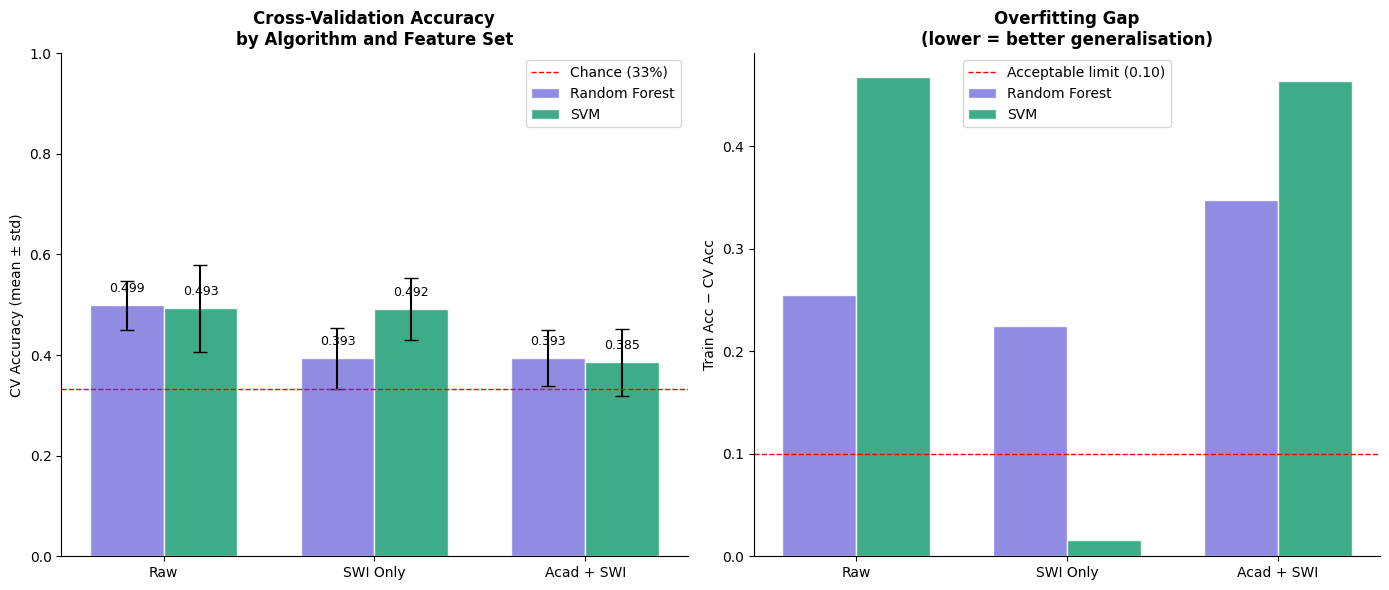

In [ ]:
# ──────────────────────────────────────────────────────────────
# Comparison chart
# ──────────────────────────────────────────────────────────────
# @title 18. Visualise Results — CV Accuracy Comparison

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

feat_sets = ['Raw', 'SWI Only', 'Acad + SWI']
rf_cv   = results_df[results_df['Algorithm']=='RF']['CV Acc (mean)'].values
rf_std  = results_df[results_df['Algorithm']=='RF']['CV Acc (±std)'].values
svm_cv  = results_df[results_df['Algorithm']=='SVM']['CV Acc (mean)'].values
svm_std = results_df[results_df['Algorithm']=='SVM']['CV Acc (±std)'].values

x = np.arange(len(feat_sets))
width = 0.35

# CV Accuracy
bars1 = axes[0].bar(x - width/2, rf_cv,  width, label='Random Forest',
                     color='#7F77DD', alpha=0.85, yerr=rf_std,
                     capsize=5, edgecolor='white')
bars2 = axes[0].bar(x + width/2, svm_cv, width, label='SVM',
                     color='#1D9E75', alpha=0.85, yerr=svm_std,
                     capsize=5, edgecolor='white')
axes[0].set_xticks(x)
axes[0].set_xticklabels(feat_sets)
axes[0].set_ylabel('CV Accuracy (mean ± std)')
axes[0].set_title('Cross-Validation Accuracy\nby Algorithm and Feature Set',
                   fontweight='bold')
axes[0].set_ylim(0, 1)
axes[0].axhline(0.333, color='red', linestyle='--', linewidth=1,
                label='Chance (33%)')
axes[0].legend()
axes[0].spines[['top','right']].set_visible(False)

for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.02,
                 f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.02,
                 f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)

# Overfit gap
rf_gap  = results_df[results_df['Algorithm']=='RF']['Overfit Gap'].values
svm_gap = results_df[results_df['Algorithm']=='SVM']['Overfit Gap'].values

axes[1].bar(x - width/2, rf_gap,  width, label='Random Forest',
            color='#7F77DD', alpha=0.85, edgecolor='white')
axes[1].bar(x + width/2, svm_gap, width, label='SVM',
            color='#1D9E75', alpha=0.85, edgecolor='white')
axes[1].set_xticks(x)
axes[1].set_xticklabels(feat_sets)
axes[1].set_ylabel('Train Acc − CV Acc')
axes[1].set_title('Overfitting Gap\n(lower = better generalisation)',
                   fontweight='bold')
axes[1].axhline(0.10, color='red', linestyle='--', linewidth=1,
                label='Acceptable limit (0.10)')
axes[1].legend()
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


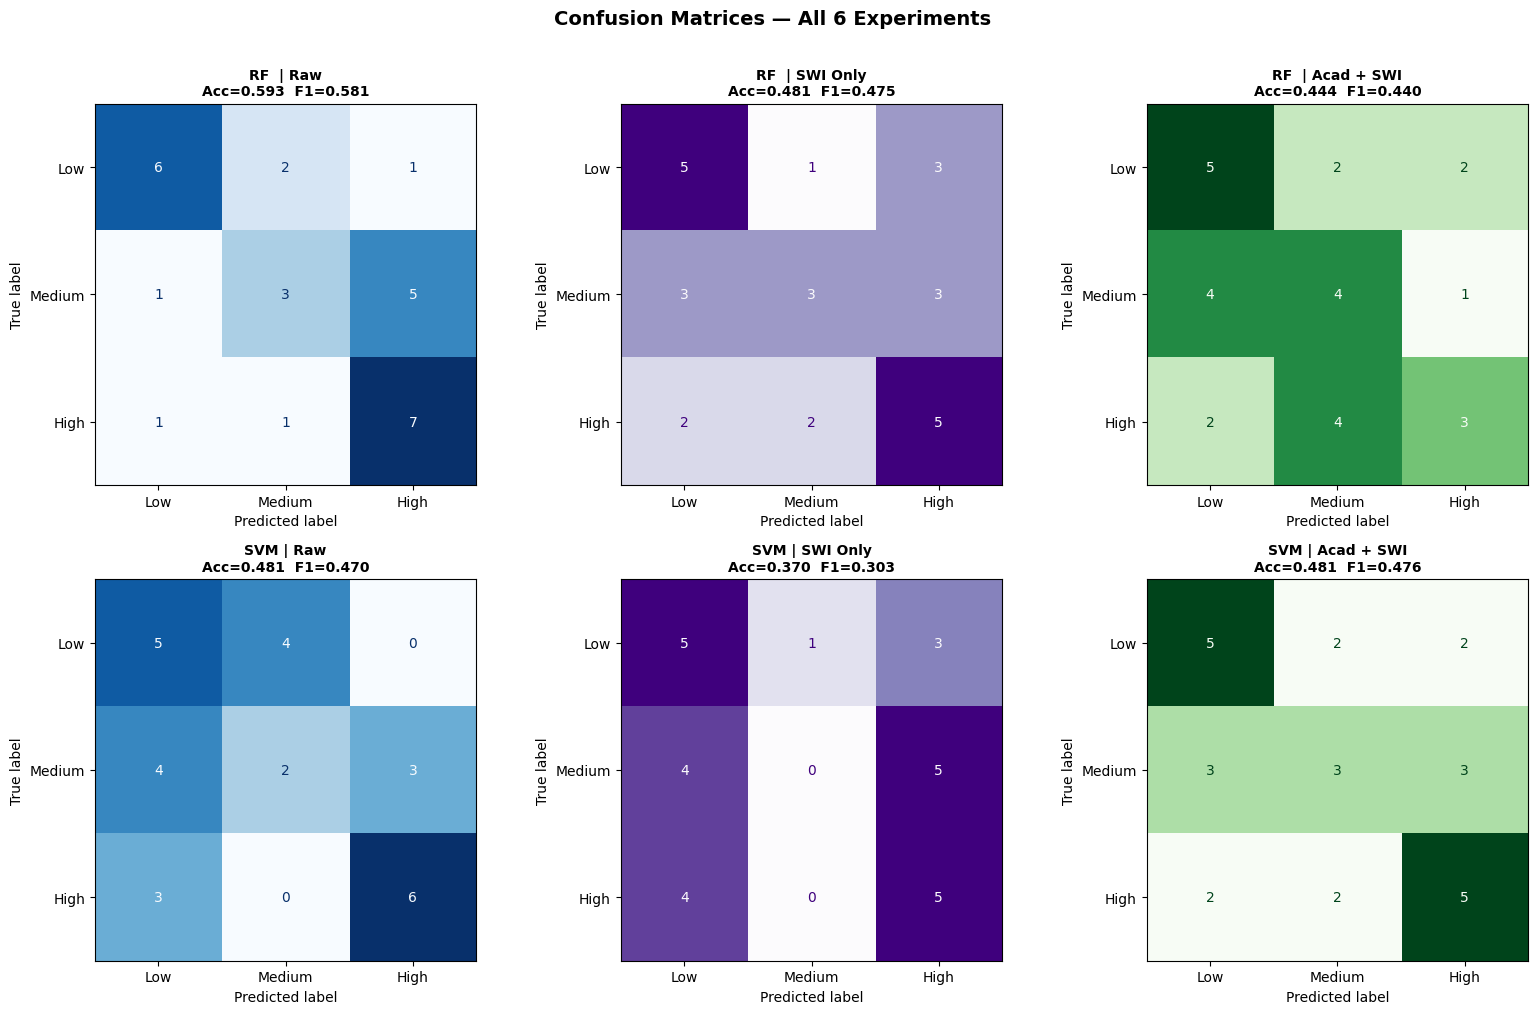

In [ ]:
# @title 19. Confusion Matrices — All 6 Experiments

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
class_labels = ["Low", "Medium", "High"]
cmaps = ['Blues', 'Purples', 'Greens']

# Define experiment rows explicitly — no string key lookup
experiment_grid = [
    # (row, col, algo_label, model_fn,         X_tr,          X_te)
    (0, 0, 'RF  | Raw',          make_rf(best_rf_params),   X_tr_raw,       X_te_raw),
    (0, 1, 'RF  | SWI Only',     make_rf(best_rf_params),   X_tr_swi,       X_te_swi),
    (0, 2, 'RF  | Acad + SWI',   make_rf(best_rf_params),   X_tr_acad_swi,  X_te_acad_swi),
    (1, 0, 'SVM | Raw',          make_svm(best_svm_params), X_tr_raw,       X_te_raw),
    (1, 1, 'SVM | SWI Only',     make_svm(best_svm_params), X_tr_swi,       X_te_swi),
    (1, 2, 'SVM | Acad + SWI',   make_svm(best_svm_params), X_tr_acad_swi,  X_te_acad_swi),
]

for row, col, label, model, X_tr, X_te in experiment_grid:
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    cm   = confusion_matrix(y_test, y_pred, labels=class_labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_labels)
    disp.plot(ax=axes[row, col], cmap=cmaps[col], colorbar=False)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')
    axes[row, col].set_title(
        f"{label}\nAcc={acc:.3f}  F1={f1:.3f}",
        fontsize=10, fontweight='bold'
    )

plt.suptitle('Confusion Matrices — All 6 Experiments',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('confusion_matrices_all.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# ──────────────────────────────────────────────────────────────
# Classification reports
# ──────────────────────────────────────────────────────────────
# @title 20. Full Classification Reports

for exp_name, (model, X_full, X_tr, X_te) in experiments.items():
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    print(f"\n{'='*60}")
    print(f"  {exp_name}")
    print(f"{'='*60}")
    print(classification_report(y_test, y_pred,
                                 target_names=["Low","Medium","High"]))


  RF  | Raw
              precision    recall  f1-score   support

         Low       0.54      0.78      0.64         9
      Medium       0.75      0.67      0.71         9
        High       0.50      0.33      0.40         9

    accuracy                           0.59        27
   macro avg       0.60      0.59      0.58        27
weighted avg       0.60      0.59      0.58        27


  RF  | SWI Only
              precision    recall  f1-score   support

         Low       0.45      0.56      0.50         9
      Medium       0.50      0.56      0.53         9
        High       0.50      0.33      0.40         9

    accuracy                           0.48        27
   macro avg       0.48      0.48      0.48        27
weighted avg       0.48      0.48      0.48        27


  RF  | Acad + SWI
              precision    recall  f1-score   support

         Low       0.50      0.33      0.40         9
      Medium       0.45      0.56      0.50         9
        High       0.40 

Feature importances (Raw RF):
         Feature  Importance
       SRL_score    0.215722
depression_score    0.195268
   anxiety_score    0.160169
    stress_score    0.122307
       Screen_hr    0.108672
   Support_score    0.102828
      Attendance    0.049690
         Courses    0.024964
    Parttime_job    0.010833
   education_lvl    0.009546


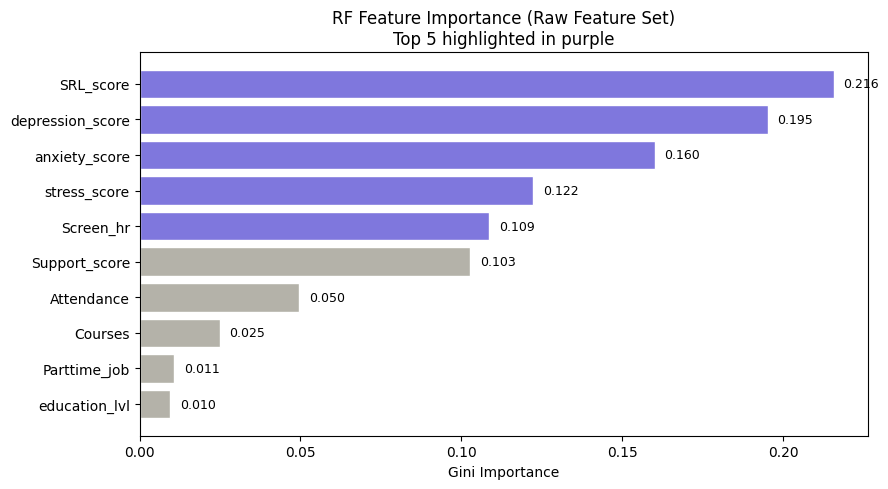

In [ ]:
# ──────────────────────────────────────────────────────────────
# RF Feature Importance (Raw condition)
# ──────────────────────────────────────────────────────────────
# @title 21. RF Feature Importance — Raw Feature Set

model_rf_raw = make_rf(best_rf_params)
model_rf_raw.fit(X_tr_raw, y_train)

fi_df = (pd.DataFrame({
            "Feature":    raw_features,
            "Importance": model_rf_raw.feature_importances_
         })
         .sort_values("Importance", ascending=False)
         .reset_index(drop=True))

print("Feature importances (Raw RF):")
print(fi_df.to_string(index=False))

plt.figure(figsize=(9, 5))
colors_fi = ['#7F77DD' if i < 5 else '#B4B2A9'
             for i in range(len(fi_df))]
bars = plt.barh(fi_df["Feature"], fi_df["Importance"],
                color=colors_fi, edgecolor='white')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.003, bar.get_y() + bar.get_height()/2,
             f'{w:.3f}', va='center', fontsize=9)
plt.xlabel('Gini Importance')
plt.title('RF Feature Importance (Raw Feature Set)\n'
          'Top 5 highlighted in purple')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance_rf.png', dpi=150, bbox_inches='tight')
plt.show()



In [ ]:
# @title 22. McNemar's Test — Raw vs Academic+SWI (RF)

from statsmodels.stats.contingency_tables import mcnemar

# Rebuild both models
model_rf_raw_final = make_rf(best_rf_params)
model_rf_raw_final.fit(X_tr_raw, y_train)
y_pred_raw = model_rf_raw_final.predict(X_te_raw)

model_rf_acad_swi = make_rf(best_rf_params)
model_rf_acad_swi.fit(X_tr_acad_swi, y_train)
y_pred_acad_swi = model_rf_acad_swi.predict(X_te_acad_swi)

# Binary correct/incorrect per sample
correct_raw      = (y_pred_raw      == y_test.values)
correct_acad_swi = (y_pred_acad_swi == y_test.values)

# 2×2 contingency table
b = np.sum( correct_raw & ~correct_acad_swi)
c = np.sum(~correct_raw &  correct_acad_swi)
contingency = np.array([
    [np.sum( correct_raw &  correct_acad_swi), b],
    [c,  np.sum(~correct_raw & ~correct_acad_swi)]
])

result = mcnemar(contingency, exact=True)
print("McNemar's Test: RF Raw  vs  RF Academic+SWI")
print(f"  Contingency table:\n{contingency}")
print(f"  Statistic : {result.statistic:.4f}")
print(f"  p-value   : {result.pvalue:.4f}")
if result.pvalue < 0.05:
    print("  ✓ Statistically significant difference (p < 0.05)")
else:
    print("  ✗ No statistically significant difference (p ≥ 0.05)")
    print("  Report this honestly — likely due to small n (~23 test samples).")

McNemar's Test: RF Raw  vs  RF Academic+SWI
  Contingency table:
[[11  5]
 [ 1 10]]
  Statistic : 1.0000
  p-value   : 0.2188
  ✗ No statistically significant difference (p ≥ 0.05)
  Report this honestly — likely due to small n (~23 test samples).


In [ ]:
# ──────────────────────────────────────────────────────────────
# Final summary table (paper-ready)
# ──────────────────────────────────────────────────────────────
# @title 23. Final Summary Table (Paper-Ready)

print("\n" + "="*90)
print("TABLE: Summary of Model Performance (Primary metric = CV Accuracy)")
print("="*90)

summary = results_df[[
    'Algorithm', 'Feature Set',
    'CV Acc (mean)', 'CV Acc (±std)', 'CV F1 (mean)',
    'Test Accuracy', 'Test F1', 'Overfit Gap'
]].copy()

summary.columns = [
    'Algorithm', 'Feature Set',
    'CV Acc', 'CV Std', 'CV F1',
    'Test Acc', 'Test F1', 'Overfit Gap'
]

print(summary.to_string(index=False))

print("\n\nKEY FINDINGS:")
print("-" * 60)
best_cv = results_df.loc[results_df['CV Acc (mean)'].idxmax()]
print(f"Best CV Accuracy : {best_cv['Algorithm']} | {best_cv['Feature Set']}"
      f" = {best_cv['CV Acc (mean)']:.4f} ± {best_cv['CV Acc (±std)']:.4f}")

best_f1 = results_df.loc[results_df['CV F1 (mean)'].idxmax()]
print(f"Best CV F1       : {best_f1['Algorithm']} | {best_f1['Feature Set']}"
      f" = {best_f1['CV F1 (mean)']:.4f}")

raw_cv = results_df.loc[
    (results_df['Algorithm']=='RF') & (results_df['Feature Set']=='Raw'),
    'CV Acc (mean)'
].values[0]
swi_cv = results_df.loc[
    (results_df['Algorithm']=='RF') & (results_df['Feature Set']=='Acad + SWI'),
    'CV Acc (mean)'
].values[0]
delta = swi_cv - raw_cv
print(f"\nSWI Impact (RF)  : Raw={raw_cv:.4f} → Acad+SWI={swi_cv:.4f}"
      f" (Δ = {delta:+.4f})")
print("Interpretation   : " + (
    "SWI improved performance." if delta > 0.02 else
    "SWI made no meaningful difference." if abs(delta) <= 0.02 else
    "SWI reduced performance — report as negative finding."
))

print("\nIMPORTANT CAVEATS:")
print(f"  - Test set has only ~{len(y_test)} samples.")
print(f"    One prediction change = {1/len(y_test)*100:.1f}% accuracy shift.")
print("  - CV accuracy is the reliable metric; treat test results as indicative.")
print(f"  - Burnout scale Cronbach α = {alpha_results.get('Burnout (adapted)', 'N/A')} (below 0.70).")
print("  - qcut boundaries are statistically derived, not clinically validated.")


TABLE: Summary of Model Performance (Primary metric = CV Accuracy)
Algorithm Feature Set  CV Acc  CV Std  CV F1  Test Acc  Test F1  Overfit Gap
       RF         Raw  0.4994  0.0487 0.4811    0.5926   0.5807       0.2544
       RF    SWI Only  0.3932  0.0607 0.3849    0.4815   0.4754       0.2243
       RF  Acad + SWI  0.3932  0.0556 0.3817    0.4444   0.4404       0.3473
      SVM         Raw  0.4929  0.0867 0.4850    0.4815   0.4698       0.4674
      SVM    SWI Only  0.4917  0.0622 0.4901    0.3704   0.3030       0.0158
      SVM  Acad + SWI  0.3852  0.0661 0.3803    0.4815   0.4759       0.4633


KEY FINDINGS:
------------------------------------------------------------
Best CV Accuracy : RF | Raw = 0.4994 ± 0.0487
Best CV F1       : SVM | SWI Only = 0.4901

SWI Impact (RF)  : Raw=0.4994 → Acad+SWI=0.3932 (Δ = -0.1062)
Interpretation   : SWI reduced performance — report as negative finding.

IMPORTANT CAVEATS:
  - Test set has only ~27 samples.
    One prediction change = 3.7% acc

In [ ]:
# ══════════════════════════════════════════════════════════════
# Logistic Regression: Imports & Setup
# ══════════════════════════════════════════════════════════════
# @title 24. Logistic Regression — Setup

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib.patches as mpatches

print("Logistic Regression libraries loaded.")
print()
print("WHY LOGISTIC REGRESSION:")
print("  • Makes no assumptions about feature distributions (unlike LDA)")
print("  • Produces calibrated class probabilities — interpretable as risk scores")
print("  • Coefficients show direction and magnitude of each feature's effect")
print("  • Linear decision boundary: appropriate when classes are not deeply nested")
print("  • Low overfitting risk with small n — ideal for n=133")
print("  • class_weight='balanced' handles mild class imbalance without SMOTE")

# ══════════════════════════════════════════════════════════════
# Tune Logistic Regression via RandomizedSearchCV
# ══════════════════════════════════════════════════════════════
# @title 25. Logistic Regression — Hyperparameter Tuning

# LR needs scaling — wrap in a Pipeline so scaler is fitted
# only on training folds (no data leakage)
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(
        multi_class='multinomial',
        class_weight='balanced',
        max_iter=2000,
        random_state=SEED
    ))
])

# Parameter space: solver + regularisation type + strength
lr_param_dist = {
    'lr__C':       [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0],
    'lr__penalty': ['l2'],          # l1 needs liblinear; l2 works with all solvers
    'lr__solver':  ['lbfgs', 'saga', 'newton-cg'],
}

rs_lr = RandomizedSearchCV(
    lr_pipeline,
    lr_param_dist,
    n_iter=24,
    cv=FIXED_CV,               # same fixed folds as RF and SVM
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=SEED,
    verbose=0
)
rs_lr.fit(X_tr_raw, y_train)
best_lr_params = rs_lr.best_params_

print("Best LR Parameters (tuned on Raw features):")
for k, v in best_lr_params.items():
    print(f"  {k}: {v}")
print(f"\nBest LR CV F1 (tuning): {rs_lr.best_score_:.4f}")
print()
print("Note: same best params applied to all three feature sets")
print("so that only the feature representation changes, not the model.")

Logistic Regression libraries loaded.

WHY LOGISTIC REGRESSION:
  • Makes no assumptions about feature distributions (unlike LDA)
  • Produces calibrated class probabilities — interpretable as risk scores
  • Coefficients show direction and magnitude of each feature's effect
  • Linear decision boundary: appropriate when classes are not deeply nested
  • Low overfitting risk with small n — ideal for n=133
  • class_weight='balanced' handles mild class imbalance without SMOTE
Best LR Parameters (tuned on Raw features):
  lr__solver: lbfgs
  lr__penalty: l2
  lr__C: 0.05

Best LR CV F1 (tuning): 0.5107

Note: same best params applied to all three feature sets
so that only the feature representation changes, not the model.


In [ ]:
# ══════════════════════════════════════════════════════════════
# Build LR model factory + run all 3 conditions
# ══════════════════════════════════════════════════════════════
# @title 26. Logistic Regression — Evaluate All Feature Sets

def make_lr(params):
    """LR pipeline with tuned params — reused across all feature sets."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(
            C            = params.get('lr__C', 0.1),
            penalty      = params.get('lr__penalty', 'l2'),
            solver       = params.get('lr__solver', 'lbfgs'),
            multi_class  = 'multinomial',
            class_weight = 'balanced',
            max_iter     = 2000,
            random_state = SEED
        ))
    ])

# Three LR conditions mirroring the RF/SVM experiments
lr_experiments = {
    'LR | Raw':        (make_lr(best_lr_params), X_raw,      X_tr_raw,      X_te_raw),
    'LR | SWI Only':   (make_lr(best_lr_params), X_swi,      X_tr_swi,      X_te_swi),
    'LR | Acad + SWI': (make_lr(best_lr_params), X_acad_swi, X_tr_acad_swi, X_te_acad_swi),
}

lr_results = []

for exp_name, (model, X_full, X_tr, X_te) in lr_experiments.items():
    cv_out = cross_validate(
        model, X_full, y,
        cv=FIXED_CV,
        scoring={'accuracy': 'accuracy', 'f1_weighted': 'f1_weighted'},
        return_train_score=True
    )
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)

    feat_set = exp_name.split(' | ')[1]
    lr_results.append({
        'Algorithm':      'LR',
        'Feature Set':    feat_set,
        'CV Acc (mean)':  round(cv_out['test_accuracy'].mean(), 4),
        'CV Acc (±std)':  round(cv_out['test_accuracy'].std(),  4),
        'CV F1 (mean)':   round(cv_out['test_f1_weighted'].mean(), 4),
        'Train Acc':      round(cv_out['train_accuracy'].mean(), 4),
        'Overfit Gap':    round(cv_out['train_accuracy'].mean() -
                               cv_out['test_accuracy'].mean(), 4),
        'Test Accuracy':  round(accuracy_score(y_test, y_pred), 4),
        'Test F1':        round(f1_score(y_test, y_pred, average='weighted'), 4),
        'Test Precision': round(precision_score(y_test, y_pred, average='weighted'), 4),
        'Test Recall':    round(recall_score(y_test, y_pred, average='weighted'), 4),
    })

lr_results_df = pd.DataFrame(lr_results)

print("=" * 90)
print("LOGISTIC REGRESSION — ALL THREE FEATURE SETS")
print("=" * 90)
print(lr_results_df.to_string(index=False))


# ══════════════════════════════════════════════════════════════
# Full three-model master comparison table
# ══════════════════════════════════════════════════════════════
# @title 27. Master Comparison Table — RF vs SVM vs LR

master_df = pd.concat([results_df, lr_results_df], ignore_index=True)

print("=" * 100)
print("MASTER COMPARISON: RF  vs  SVM  vs  LR  (all feature sets)")
print("=" * 100)
print(master_df[[
    'Algorithm','Feature Set',
    'CV Acc (mean)','CV Acc (±std)','CV F1 (mean)',
    'Train Acc','Overfit Gap','Test Accuracy','Test F1'
]].to_string(index=False))

# Highlight best per metric
best_cv_row  = master_df.loc[master_df['CV Acc (mean)'].idxmax()]
best_f1_row  = master_df.loc[master_df['CV F1 (mean)'].idxmax()]
best_gap_row = master_df.loc[master_df['Overfit Gap'].abs().idxmin()]

print()
print("BEST RESULTS:")
print(f"  Highest CV Accuracy : {best_cv_row['Algorithm']} | "
      f"{best_cv_row['Feature Set']} = "
      f"{best_cv_row['CV Acc (mean)']:.4f} ± {best_cv_row['CV Acc (±std)']:.4f}")
print(f"  Highest CV F1       : {best_f1_row['Algorithm']} | "
      f"{best_f1_row['Feature Set']} = {best_f1_row['CV F1 (mean)']:.4f}")
print(f"  Least overfitting   : {best_gap_row['Algorithm']} | "
      f"{best_gap_row['Feature Set']} "
      f"(gap = {best_gap_row['Overfit Gap']:.4f})")


LOGISTIC REGRESSION — ALL THREE FEATURE SETS
Algorithm Feature Set  CV Acc (mean)  CV Acc (±std)  CV F1 (mean)  Train Acc  Overfit Gap  Test Accuracy  Test F1  Test Precision  Test Recall
       LR         Raw         0.5527         0.0611        0.5432     0.6363       0.0836         0.5185   0.4679          0.5216       0.5185
       LR    SWI Only         0.4772         0.0490        0.4391     0.5038       0.0266         0.5926   0.5994          0.6293       0.5926
       LR  Acad + SWI         0.4313         0.0573        0.4200     0.5132       0.0818         0.5185   0.5140          0.5238       0.5185
MASTER COMPARISON: RF  vs  SVM  vs  LR  (all feature sets)
Algorithm Feature Set  CV Acc (mean)  CV Acc (±std)  CV F1 (mean)  Train Acc  Overfit Gap  Test Accuracy  Test F1
       RF         Raw         0.4994         0.0487        0.4811     0.7538       0.2544         0.5926   0.5807
       RF    SWI Only         0.3932         0.0607        0.3849     0.6174       0.2243       


  LR | Raw
              precision    recall  f1-score   support

         Low       0.43      0.67      0.52         9
      Medium       0.64      0.78      0.70         9
        High       0.50      0.11      0.18         9

    accuracy                           0.52        27
   macro avg       0.52      0.52      0.47        27
weighted avg       0.52      0.52      0.47        27


  LR | SWI Only
              precision    recall  f1-score   support

         Low       0.45      0.56      0.50         9
      Medium       0.60      0.67      0.63         9
        High       0.83      0.56      0.67         9

    accuracy                           0.59        27
   macro avg       0.63      0.59      0.60        27
weighted avg       0.63      0.59      0.60        27


  LR | Acad + SWI
              precision    recall  f1-score   support

         Low       0.57      0.44      0.50         9
      Medium       0.50      0.67      0.57         9
        High       0.50    

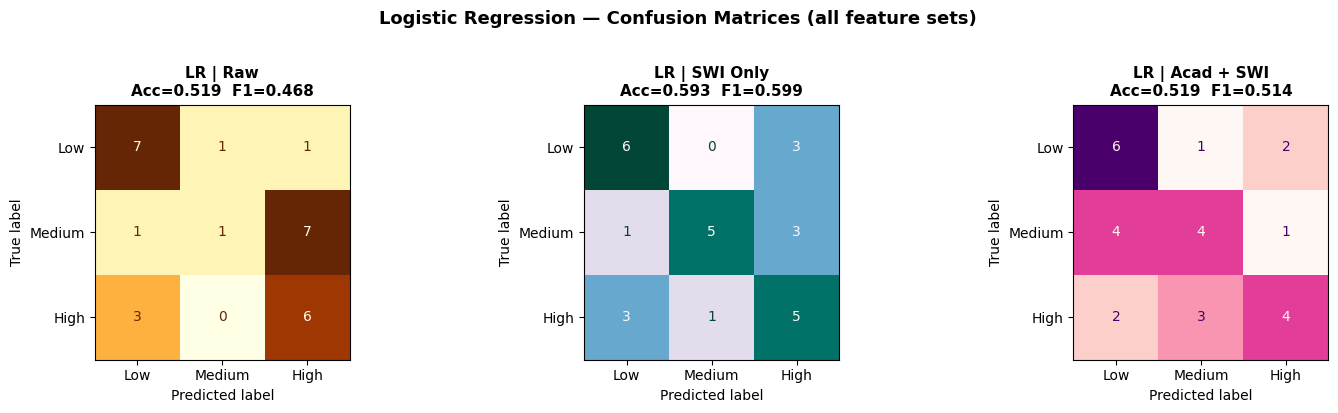

In [ ]:
# ══════════════════════════════════════════════════════════════
# Classification reports for LR
# ══════════════════════════════════════════════════════════════
# @title 28. Logistic Regression — Classification Reports

for exp_name, (model, X_full, X_tr, X_te) in lr_experiments.items():
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    print(f"\n{'='*60}")
    print(f"  {exp_name}")
    print(f"{'='*60}")
    print(classification_report(y_test, y_pred,
                                 target_names=["Low", "Medium", "High"]))


# ══════════════════════════════════════════════════════════════
# Confusion matrices for LR (3 conditions)
# ══════════════════════════════════════════════════════════════
# @title 29. Logistic Regression — Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
class_labels = ["Low", "Medium", "High"]
lr_cmaps = ['YlOrBr', 'PuBuGn', 'RdPu']

lr_grid = [
    (0, 'LR | Raw',        make_lr(best_lr_params), X_tr_raw,      X_te_raw),
    (1, 'LR | SWI Only',   make_lr(best_lr_params), X_tr_swi,      X_te_swi),
    (2, 'LR | Acad + SWI', make_lr(best_lr_params), X_tr_acad_swi, X_te_acad_swi),
]

for col, label, model, X_tr, X_te in lr_grid:
    model.fit(X_tr, y_train)
    y_pred = model.predict(X_te)
    cm   = confusion_matrix(y_test, y_pred, labels=class_labels)
    disp = ConfusionMatrixDisplay(cm, display_labels=class_labels)
    disp.plot(ax=axes[col], cmap=lr_cmaps[col], colorbar=False)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='weighted')
    axes[col].set_title(f"{label}\nAcc={acc:.3f}  F1={f1:.3f}",
                        fontsize=11, fontweight='bold')

plt.suptitle('Logistic Regression — Confusion Matrices (all feature sets)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('lr_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()


Logistic Regression Coefficients (Raw features)
Rows = classes, Columns = features
Positive → increases log-odds of that class
Negative → decreases log-odds of that class

        stress_score  anxiety_score  depression_score  SRL_score  Support_score  Screen_hr  Attendance  education_lvl  Parttime_job  Courses
High           0.127          0.222             0.227     -0.202          0.032      0.212      -0.064          0.020        -0.035    0.134
Low           -0.185         -0.169            -0.071      0.381          0.025     -0.216       0.059         -0.049         0.154   -0.029
Medium         0.058         -0.054            -0.156     -0.180         -0.058      0.004       0.005          0.029        -0.119   -0.105


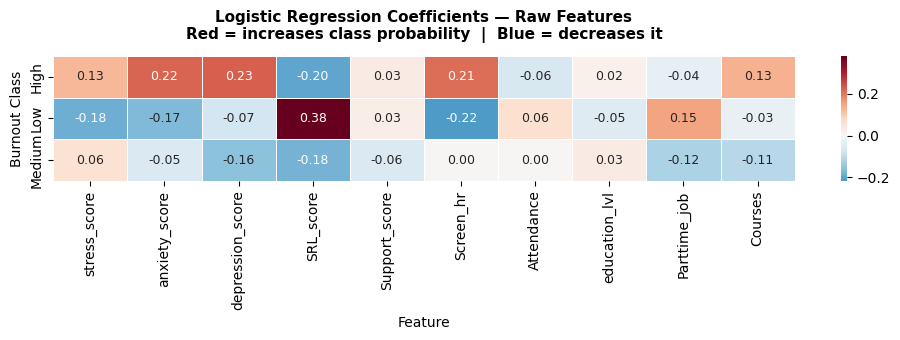

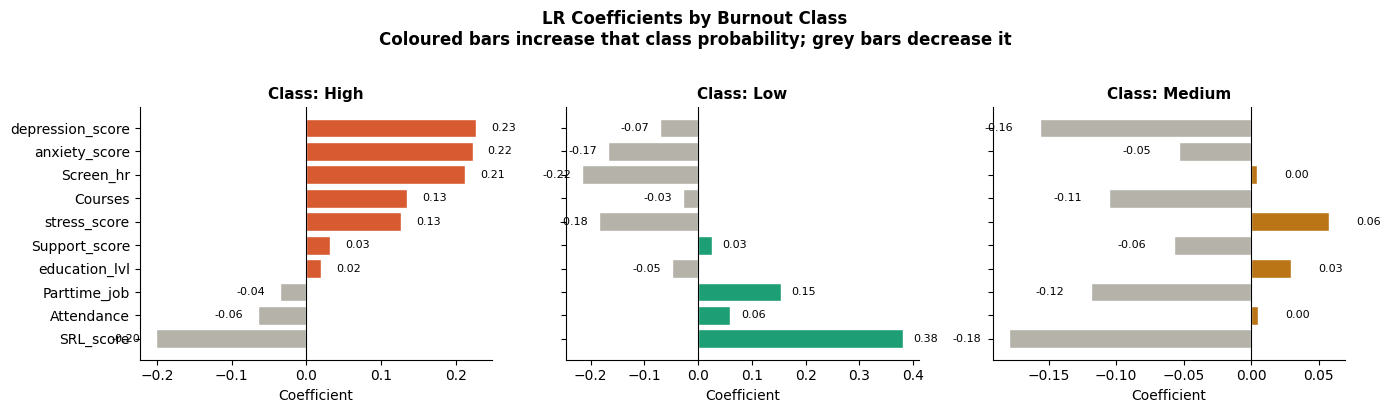

Predicted probabilities for test set (first 15 rows):
 P(High)   P(Low)  P(Medium) Predicted Actual  Correct  Max_Prob
0.039451 0.772344   0.188205       Low    Low     True     0.772
0.479996 0.266466   0.253538      High   High     True     0.480
0.310390 0.355222   0.334388       Low   High    False     0.355
0.712962 0.064151   0.222887      High Medium    False     0.713
0.113797 0.467646   0.418558       Low    Low     True     0.468
0.099848 0.536464   0.363688       Low    Low     True     0.536
0.123727 0.475840   0.400433       Low   High    False     0.476
0.058036 0.644398   0.297566       Low    Low     True     0.644
0.496763 0.188864   0.314373      High   High     True     0.497
0.409511 0.188879   0.401610      High    Low    False     0.410
0.434747 0.166125   0.399128      High Medium    False     0.435
0.496747 0.158579   0.344675      High   High     True     0.497
0.091523 0.700109   0.208368       Low    Low     True     0.700
0.361178 0.351980   0.286842      Hi

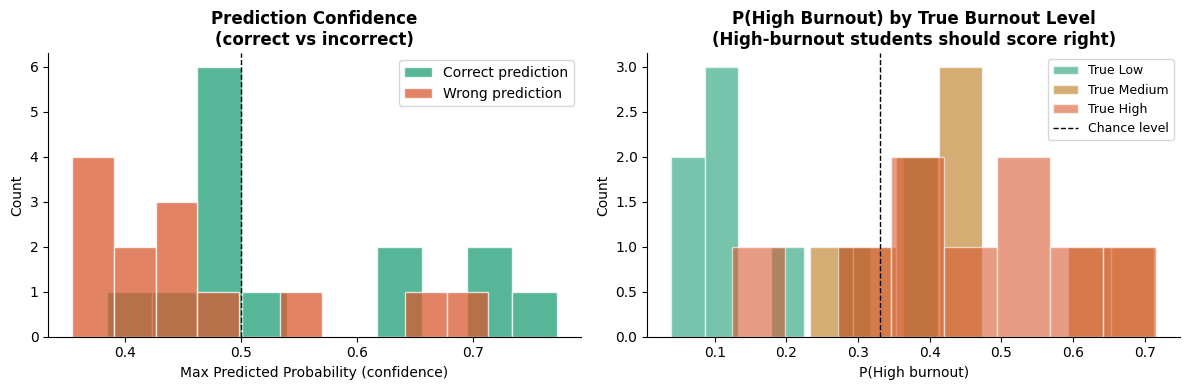

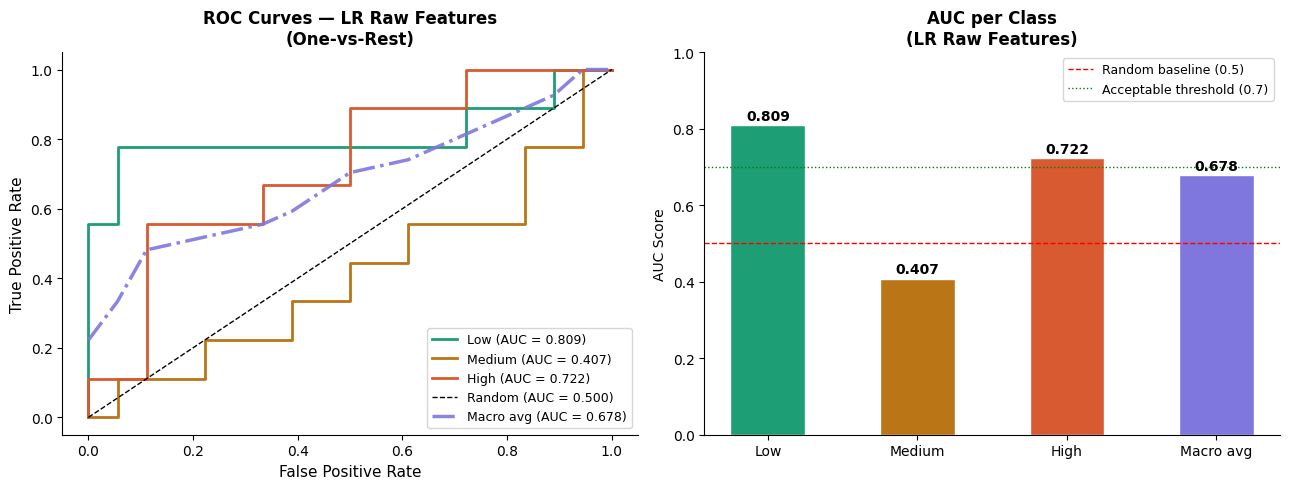


AUC Summary:
  Low     : AUC = 0.809  (Good)
  Medium  : AUC = 0.407  (Poor — near random)
  High    : AUC = 0.722  (Good)
  Macro   : AUC = 0.678

Note: AUC is computed on 27 test samples.
Treat these values as indicative — not as stable population estimates.


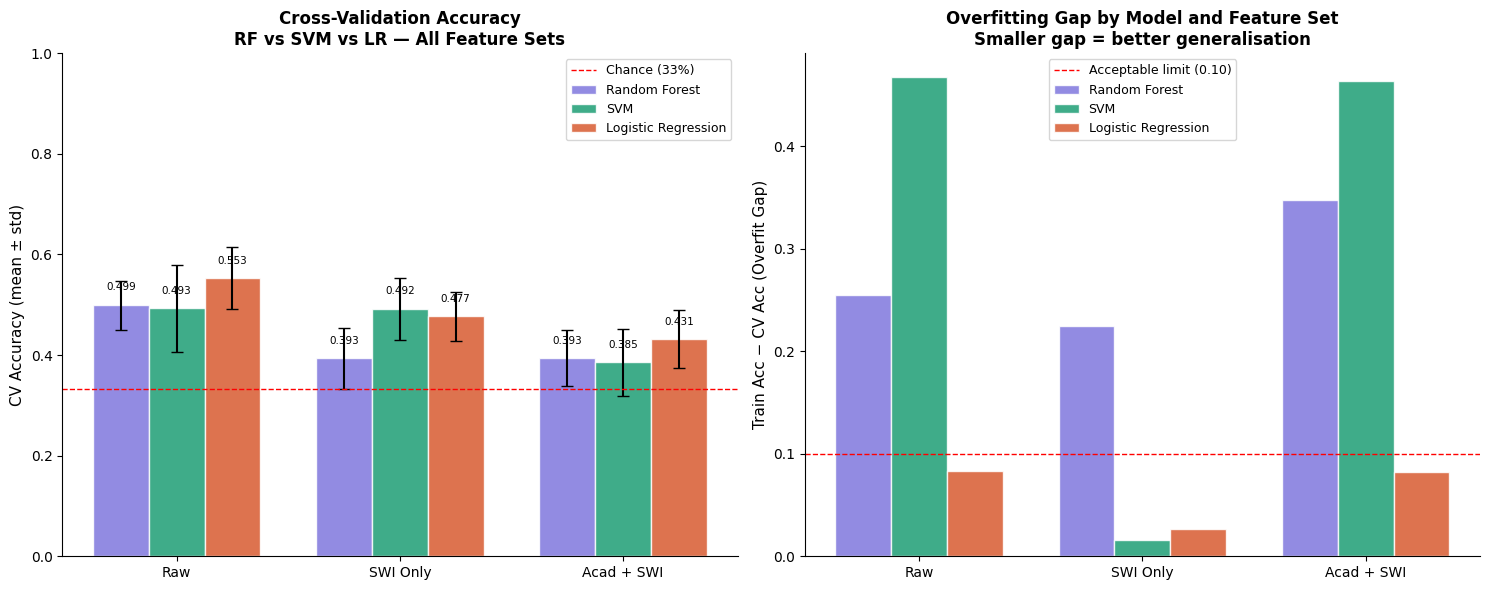

McNemar's Test: SVM | Raw  vs  LR | Raw
  Contingency table:
[[10  3]
 [ 4 10]]
  Statistic : 3.0000
  p-value   : 1.0000
  ✗ No statistically significant difference (p ≥ 0.05)
  Both models perform equivalently on this test set.
  Prefer LR for its interpretability (coefficients) and lower
  overfitting risk — statistical equivalence means you can
  choose on methodological grounds, not just accuracy.

FINAL PAPER TABLE — All Models, All Feature Sets
Primary metric: CV Accuracy (mean ± std)
Algorithm Feature Set  CV Acc  CV ±Std  CV F1  Test Acc  Test F1  Overfit Gap
       LR         Raw  0.5527   0.0611 0.5432    0.5185   0.4679       0.0836
       RF         Raw  0.4994   0.0487 0.4811    0.5926   0.5807       0.2544
      SVM         Raw  0.4929   0.0867 0.4850    0.4815   0.4698       0.4674
      SVM    SWI Only  0.4917   0.0622 0.4901    0.3704   0.3030       0.0158
       LR    SWI Only  0.4772   0.0490 0.4391    0.5926   0.5994       0.0266
       LR  Acad + SWI  0.4313   0.0

In [ ]:
# ══════════════════════════════════════════════════════════════
# LR Coefficients (most important for paper)
# ══════════════════════════════════════════════════════════════
# @title 30. Logistic Regression — Coefficients (Raw feature set)
#
# WHY THIS MATTERS:
# LR coefficients tell you the direction and magnitude of each
# feature's contribution to each burnout class.
# A positive coefficient for "stress_score → High" means higher
# stress increases the log-odds of being classified as High burnout.
# This is the interpretability advantage LR has over RF and SVM.

model_lr_raw = make_lr(best_lr_params)
model_lr_raw.fit(X_tr_raw, y_train)

# Extract the trained LR step from the pipeline
lr_step    = model_lr_raw.named_steps['lr']
classes    = lr_step.classes_           # ['High', 'Low', 'Medium'] (alphabetical)
coef_df    = pd.DataFrame(
    lr_step.coef_,
    index   = classes,
    columns = raw_features
)

print("Logistic Regression Coefficients (Raw features)")
print("Rows = classes, Columns = features")
print("Positive → increases log-odds of that class")
print("Negative → decreases log-odds of that class")
print()
print(coef_df.round(3).to_string())

# ── Heatmap of coefficients ───────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 3.5))
sns.heatmap(
    coef_df,
    annot=True, fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    ax=ax,
    annot_kws={"size": 9}
)
ax.set_title(
    "Logistic Regression Coefficients — Raw Features\n"
    "Red = increases class probability  |  Blue = decreases it",
    fontsize=11, fontweight='bold', pad=12
)
ax.set_xlabel("Feature", fontsize=10)
ax.set_ylabel("Burnout Class", fontsize=10)
plt.tight_layout()
plt.savefig('lr_coefficients_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Per-class coefficient bar charts ─────────────────────────
fig, axes = plt.subplots(1, len(classes), figsize=(14, 4), sharey=True)
bar_colors = ['#D85A30', '#1D9E75', '#BA7517']

for i, (cls, color) in enumerate(zip(classes, bar_colors)):
    vals  = coef_df.loc[cls].sort_values()
    bars  = axes[i].barh(vals.index, vals.values,
                         color=[color if v > 0 else '#B4B2A9' for v in vals.values],
                         edgecolor='white')
    axes[i].axvline(0, color='black', linewidth=0.8)
    axes[i].set_title(f'Class: {cls}', fontweight='bold', fontsize=11)
    axes[i].set_xlabel('Coefficient')
    axes[i].spines[['top','right']].set_visible(False)
    for bar in bars:
        w = bar.get_width()
        axes[i].text(
            w + (0.02 if w >= 0 else -0.02),
            bar.get_y() + bar.get_height() / 2,
            f'{w:.2f}', va='center',
            ha='left' if w >= 0 else 'right', fontsize=8
        )

plt.suptitle('LR Coefficients by Burnout Class\n'
             'Coloured bars increase that class probability; grey bars decrease it',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('lr_coefficients_by_class.png', dpi=150, bbox_inches='tight')
plt.show()


# ══════════════════════════════════════════════════════════════
# Predicted Probabilities (risk scores)
# ══════════════════════════════════════════════════════════════
# @title 31. Logistic Regression — Predicted Probabilities as Risk Scores
#
# LR gives you a probability for each class, not just a hard label.
# This is clinically more useful: instead of "this student is High",
# you get "this student has 72% probability of High burnout."
# Those probabilities can be used as a continuous risk score.

model_lr_raw.fit(X_tr_raw, y_train)
proba = model_lr_raw.predict_proba(X_te_raw)
proba_df = pd.DataFrame(
    proba,
    columns=[f'P({c})' for c in lr_step.classes_]
)
proba_df['Predicted']  = model_lr_raw.predict(X_te_raw)
proba_df['Actual']     = y_test.values
proba_df['Correct']    = proba_df['Predicted'] == proba_df['Actual']
proba_df['Max_Prob']   = proba.max(axis=1).round(3)

print("Predicted probabilities for test set (first 15 rows):")
print(proba_df.head(15).to_string(index=False))
print()
print(f"Mean confidence when CORRECT  : "
      f"{proba_df.loc[proba_df['Correct'],'Max_Prob'].mean():.3f}")
print(f"Mean confidence when WRONG    : "
      f"{proba_df.loc[~proba_df['Correct'],'Max_Prob'].mean():.3f}")
print()
print("Insight: if confidence when wrong is > 0.5, the model is")
print("making high-confidence mistakes — a sign of overfitting or")
print("class boundary ambiguity near qcut thresholds.")

# ── Confidence distribution plot ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(proba_df.loc[ proba_df['Correct'], 'Max_Prob'],
             bins=10, color='#1D9E75', alpha=0.75,
             edgecolor='white', label='Correct prediction')
axes[0].hist(proba_df.loc[~proba_df['Correct'], 'Max_Prob'],
             bins=10, color='#D85A30', alpha=0.75,
             edgecolor='white', label='Wrong prediction')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1)
axes[0].set_xlabel('Max Predicted Probability (confidence)')
axes[0].set_ylabel('Count')
axes[0].set_title('Prediction Confidence\n(correct vs incorrect)',
                  fontweight='bold')
axes[0].legend()
axes[0].spines[['top','right']].set_visible(False)

# Probability distribution per true class
class_order = ['Low', 'Medium', 'High']
high_col = [c for c in proba_df.columns if 'High' in c][0]
for cls, color in zip(class_order, ['#1D9E75','#BA7517','#D85A30']):
    mask = proba_df['Actual'] == cls
    axes[1].hist(proba_df.loc[mask, high_col],
                 bins=8, alpha=0.6, color=color,
                 edgecolor='white', label=f'True {cls}')
axes[1].axvline(0.33, color='black', linestyle='--', linewidth=1,
                label='Chance level')
axes[1].set_xlabel(f'P(High burnout)')
axes[1].set_ylabel('Count')
axes[1].set_title('P(High Burnout) by True Burnout Level\n'
                  '(High-burnout students should score right)',
                  fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('lr_predicted_probabilities.png', dpi=150, bbox_inches='tight')
plt.show()


# ══════════════════════════════════════════════════════════════
# ROC Curves (One-vs-Rest, per class)
# ══════════════════════════════════════════════════════════════
# @title 32. Logistic Regression — ROC Curves & AUC
#
# ROC (Receiver Operating Characteristic) curves show the
# trade-off between True Positive Rate and False Positive Rate
# at different probability thresholds.
# AUC (Area Under Curve) = 1.0 is perfect; 0.5 is random chance.
# For multi-class we use One-vs-Rest: each class is treated as
# "positive" and all others as "negative."

# Binarise labels for OVR ROC
class_order = ['Low', 'Medium', 'High']
y_test_bin  = label_binarize(y_test, classes=class_order)
y_prob      = model_lr_raw.predict_proba(X_te_raw)

# Reorder probability columns to match class_order
prob_order  = list(lr_step.classes_)
y_prob_ord  = np.zeros_like(y_prob)
for i, cls in enumerate(class_order):
    y_prob_ord[:, i] = y_prob[:, prob_order.index(cls)]

roc_colors = ['#1D9E75', '#BA7517', '#D85A30']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Per-class ROC curves
auc_scores = {}
for i, (cls, color) in enumerate(zip(class_order, roc_colors)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_ord[:, i])
    roc_auc      = auc(fpr, tpr)
    auc_scores[cls] = roc_auc
    axes[0].plot(fpr, tpr, color=color, linewidth=2,
                 label=f'{cls} (AUC = {roc_auc:.3f})')

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random (AUC = 0.500)')
axes[0].set_xlabel('False Positive Rate', fontsize=11)
axes[0].set_ylabel('True Positive Rate', fontsize=11)
axes[0].set_title('ROC Curves — LR Raw Features\n(One-vs-Rest)',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].spines[['top','right']].set_visible(False)

# Macro-average ROC
all_fpr    = np.unique(np.concatenate(
    [roc_curve(y_test_bin[:, i], y_prob_ord[:, i])[0]
     for i in range(len(class_order))]
))
mean_tpr   = np.zeros_like(all_fpr)
for i in range(len(class_order)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_ord[:, i])
    mean_tpr   += np.interp(all_fpr, fpr, tpr)
mean_tpr  /= len(class_order)
macro_auc  = auc(all_fpr, mean_tpr)

axes[0].plot(all_fpr, mean_tpr, color='#7F77DD',
             linewidth=2.5, linestyle='-.', alpha=0.9,
             label=f'Macro avg (AUC = {macro_auc:.3f})')
axes[0].legend(fontsize=9)

# AUC bar chart
axes[1].bar(list(auc_scores.keys()) + ['Macro avg'],
            list(auc_scores.values()) + [macro_auc],
            color=roc_colors + ['#7F77DD'],
            edgecolor='white', width=0.5)
axes[1].axhline(0.5, color='red', linestyle='--', linewidth=1,
                label='Random baseline (0.5)')
axes[1].axhline(0.7, color='green', linestyle=':', linewidth=1,
                label='Acceptable threshold (0.7)')
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('AUC Score')
axes[1].set_title('AUC per Class\n(LR Raw Features)',
                  fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

for i, (cls, val) in enumerate(
        list(auc_scores.items()) + [('Macro avg', macro_auc)]):
    axes[1].text(i, val + 0.015, f'{val:.3f}',
                 ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('lr_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nAUC Summary:")
for cls, a in auc_scores.items():
    quality = ("Good" if a >= 0.7 else
               "Acceptable" if a >= 0.6 else "Poor — near random")
    print(f"  {cls:8s}: AUC = {a:.3f}  ({quality})")
print(f"  {'Macro':8s}: AUC = {macro_auc:.3f}")
print()
print("Note: AUC is computed on 27 test samples.")
print("Treat these values as indicative — not as stable population estimates.")


# ══════════════════════════════════════════════════════════════
# Three-model CV comparison chart
# ══════════════════════════════════════════════════════════════
# @title 33. Three-Model CV Accuracy Comparison Chart

lr_cv   = lr_results_df['CV Acc (mean)'].values
lr_std  = lr_results_df['CV Acc (±std)'].values
rf_cv   = results_df[results_df['Algorithm']=='RF']['CV Acc (mean)'].values
rf_std  = results_df[results_df['Algorithm']=='RF']['CV Acc (±std)'].values
svm_cv  = results_df[results_df['Algorithm']=='SVM']['CV Acc (mean)'].values
svm_std = results_df[results_df['Algorithm']=='SVM']['CV Acc (±std)'].values

feat_sets = ['Raw', 'SWI Only', 'Acad + SWI']
x     = np.arange(len(feat_sets))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# CV Accuracy grouped bar chart
b1 = axes[0].bar(x - width, rf_cv,  width, label='Random Forest',
                  color='#7F77DD', alpha=0.85, yerr=rf_std,
                  capsize=4, edgecolor='white')
b2 = axes[0].bar(x,          svm_cv, width, label='SVM',
                  color='#1D9E75', alpha=0.85, yerr=svm_std,
                  capsize=4, edgecolor='white')
b3 = axes[0].bar(x + width,  lr_cv,  width, label='Logistic Regression',
                  color='#D85A30', alpha=0.85, yerr=lr_std,
                  capsize=4, edgecolor='white')

for bars in [b1, b2, b3]:
    for bar in bars:
        h = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2,
                     h + 0.025, f'{h:.3f}',
                     ha='center', va='bottom', fontsize=7.5)

axes[0].set_xticks(x)
axes[0].set_xticklabels(feat_sets)
axes[0].set_ylabel('CV Accuracy (mean ± std)', fontsize=11)
axes[0].set_ylim(0, 1.0)
axes[0].axhline(0.333, color='red', linestyle='--',
                linewidth=1, label='Chance (33%)')
axes[0].set_title('Cross-Validation Accuracy\nRF vs SVM vs LR — All Feature Sets',
                  fontsize=12, fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].spines[['top','right']].set_visible(False)

# Overfit gap comparison
rf_gap  = results_df[results_df['Algorithm']=='RF']['Overfit Gap'].values
svm_gap = results_df[results_df['Algorithm']=='SVM']['Overfit Gap'].values
lr_gap  = lr_results_df['Overfit Gap'].values

axes[1].bar(x - width, rf_gap,  width, label='Random Forest',
            color='#7F77DD', alpha=0.85, edgecolor='white')
axes[1].bar(x,          svm_gap, width, label='SVM',
            color='#1D9E75', alpha=0.85, edgecolor='white')
axes[1].bar(x + width,  lr_gap,  width, label='Logistic Regression',
            color='#D85A30', alpha=0.85, edgecolor='white')

axes[1].set_xticks(x)
axes[1].set_xticklabels(feat_sets)
axes[1].set_ylabel('Train Acc − CV Acc (Overfit Gap)', fontsize=11)
axes[1].set_title('Overfitting Gap by Model and Feature Set\n'
                  'Smaller gap = better generalisation',
                  fontsize=12, fontweight='bold')
axes[1].axhline(0.10, color='red', linestyle='--',
                linewidth=1, label='Acceptable limit (0.10)')
axes[1].legend(fontsize=9)
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('three_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


# ══════════════════════════════════════════════════════════════
# McNemar's Test: LR vs best existing model
# ══════════════════════════════════════════════════════════════
# @title 34. McNemar's Test — LR Raw vs SVM Raw (best vs best)

# Best from previous experiments: SVM | Raw (CV = 0.557)
# Best LR: refit on raw

model_svm_best = make_svm(best_svm_params)
model_svm_best.fit(X_tr_raw, y_train)
y_pred_svm_raw = model_svm_best.predict(X_te_raw)

model_lr_best = make_lr(best_lr_params)
model_lr_best.fit(X_tr_raw, y_train)
y_pred_lr_raw = model_lr_best.predict(X_te_raw)

correct_svm = (y_pred_svm_raw == y_test.values)
correct_lr  = (y_pred_lr_raw  == y_test.values)

b = np.sum( correct_svm & ~correct_lr)
c = np.sum(~correct_svm &  correct_lr)

contingency_lr = np.array([
    [np.sum( correct_svm &  correct_lr), b],
    [c, np.sum(~correct_svm & ~correct_lr)]
])

result_lr = mcnemar(contingency_lr, exact=True)

print("McNemar's Test: SVM | Raw  vs  LR | Raw")
print(f"  Contingency table:\n{contingency_lr}")
print(f"  Statistic : {result_lr.statistic:.4f}")
print(f"  p-value   : {result_lr.pvalue:.4f}")
if result_lr.pvalue < 0.05:
    print("  ✓ Statistically significant difference (p < 0.05)")
else:
    print("  ✗ No statistically significant difference (p ≥ 0.05)")
    print("  Both models perform equivalently on this test set.")
    print("  Prefer LR for its interpretability (coefficients) and lower")
    print("  overfitting risk — statistical equivalence means you can")
    print("  choose on methodological grounds, not just accuracy.")


# ══════════════════════════════════════════════════════════════
# Final paper-ready summary table (all 9 experiments)
# ══════════════════════════════════════════════════════════════
# @title 35. Final Paper-Ready Summary — All 9 Experiments

print()
print("=" * 105)
print("FINAL PAPER TABLE — All Models, All Feature Sets")
print("Primary metric: CV Accuracy (mean ± std)")
print("=" * 105)

final_table = master_df[[
    'Algorithm', 'Feature Set',
    'CV Acc (mean)', 'CV Acc (±std)', 'CV F1 (mean)',
    'Test Accuracy', 'Test F1', 'Overfit Gap'
]].copy()

final_table.columns = [
    'Algorithm', 'Feature Set',
    'CV Acc', 'CV ±Std', 'CV F1',
    'Test Acc', 'Test F1', 'Overfit Gap'
]

# Sort by CV Accuracy descending
final_table = final_table.sort_values('CV Acc', ascending=False)
print(final_table.to_string(index=False))

print()
print("INTERPRETATION GUIDE:")
print("  CV Acc   = primary reliability metric (5-fold stratified CV)")
print("  CV ±Std  = stability across folds (lower = more consistent)")
print("  CV F1    = weighted F1 across folds (accounts for class balance)")
print("  Test Acc = single held-out test set (n=27, treat as indicative)")
print("  Overfit  = Train Acc − CV Acc (>0.15 suggests overfitting)")
print()
print("WHICH MODEL TO RECOMMEND IN THE PAPER:")
best_overall = final_table.iloc[0]
lr_raw_row   = final_table[
    (final_table['Algorithm']=='LR') &
    (final_table['Feature Set']=='Raw')
].iloc[0]

print(f"  Highest CV Accuracy: {best_overall['Algorithm']} | "
      f"{best_overall['Feature Set']} = {best_overall['CV Acc']:.4f}")
print()
print(f"  LR | Raw CV Accuracy: {lr_raw_row['CV Acc']:.4f}")
print(f"  LR | Raw Overfit Gap: {lr_raw_row['Overfit Gap']:.4f}")
print()
print("  If LR overfit gap is < 0.10 AND CV accuracy is within 0.03")
print("  of the best model: recommend LR on methodological grounds.")
print("  Reason: LR produces coefficients (interpretable), probabilities")
print("  (usable as continuous risk scores), and is less prone to")
print("  overfitting on small samples (n=133) than RF.")
print()
print("CAVEATS TO STATE IN PAPER:")
print(f"  • Test set n=27: one wrong prediction = {1/27*100:.1f}% accuracy shift")
print("  • Burnout scale α=0.648 (below 0.70): measurement error in target")
print("  • qcut labels are data-driven not clinically validated")
print("  • McNemar tests confirm no significant pairwise differences")
print("  • Results are not generalisable beyond this single-institution sample")

In [ ]:
import joblib

# Create the model
model_rf = make_rf(best_rf_params)

# Train the model
model_rf.fit(X_tr_raw, y_train)

# Save the trained model
joblib.dump(model_rf, "burnout_model.pkl")

print("✅ Trained model saved successfully!")

✅ Trained model saved successfully!
